In [ ]:
#| default_exp challenge_analysis.challenge_phase

## Input files used

- `data/challenge_phase/team_mapping.txt`
- `path_folders/team_mapping.txt`
- `data/challenge_phase/final_leaderboards/Final_leaderboard_{videos,trajs}_single.csv`
- `data/challenge_phase/scores_post15/df_track_{1,2}_task_1_{letter}.csv`
- `path_folders/final_leaderboards/Final_leaderboard_trajs_single.csv`
- `path_folders/analysis_data/metrics_vs_cp.npy`
- `figures/df_single_state.csv`
- `path_folders/submissions_post15/{letter}/track_2/exp_{exp}/fov_{fov}.txt`
- `path_folders/reference_challenge_phase/track_2/exp_{exp}/traj_labs_fov_{fov}.txt`

# LIBS 

In [1]:
#| export
import numpy as np 

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


import os
import re
import zipfile
import string
from tqdm.notebook import tqdm
import pandas as pd
pd.options.mode.chained_assignment = None

import pathlib
from scipy.stats import rankdata

from scipy.stats import gaussian_kde


from git import Repo
current_branch = Repo('/home/gorka/github/andi_datasets/').active_branch.name
print(f"andi_datasets is in '{current_branch}' branch")


from andi_datasets.utils_challenge import (run_ensemble_task, error_Ensemble_dataset, load_file_to_df,
                                           multimode_dist, codalab_scoring_local, _get_error_bounds, 
                                            error_Ensemble_dataset, error_SingleTraj_dataset, distribution_distance)
import andi_datasets.utils_challenge as andi_utils
from andi_datasets.models_phenom import models_phenom
from andi_datasets.analysis import msd_analysis
from andi_datasets.datasets_phenom import datasets_phenom


PATH = pathlib.Path('data/challenge_phase/')


def load_txt_as_dict(file_path):
    dictionary = {}
    
    with open(file_path, 'r') as file:
        lines = file.readlines()
        
        for line in lines:
            key, value = line.strip().split(': ')
            dictionary[key] = value
    
    return dictionary


#### Params
num_fovs = 30
correct_exps = np.array([2,3,4,6,7,8,9,10,11]) 
groups = [[0, 1, 2], [3], [4], [5, 6], [7], [8]]

order_exps_paper = np.array([3,4,5,1,2,6,7,8,9])-1

andi_datasets is in 'master' branch


In [2]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from tqdm.notebook import tqdm

c_main = '#2790DB'
c_comp = '#DB403D'
c_comp2 = '#2DBD59'
c_grey = '#a3a3a3'
white = '#FFFFFF'
black = '#000000'

import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('custom_cmap', [c_main, c_comp], N=250)  # N is the number of discrete colors
cmap_b = LinearSegmentedColormap.from_list('custom_cmap', [c_main, black], N=250)  # N is the number of discrete colors
cmap_r = LinearSegmentedColormap.from_list('custom_cmap', [c_comp, white], N=250)  # N is the number of discrete colors

# example colors
colors = cmap(np.linspace(0, 1, 10))

golden_ratio = (1 + 5 ** 0.5) / 2  # Approximately 1.618
width = 5
height = width / golden_ratio

def put_label(ax, label):
    ax.text(0, 1.1, label, transform=ax.transAxes,
           fontsize=16, fontweight='bold', va='top', ha='left')

In [3]:
path_folders = '/media/gorka/DATA/andi2_data/datasets_phases_challenge/challenge_phase/'
path_pred = lambda letter, track, exp, fov: path_folders+f'submissions_post15/{letter}/track_{track}/exp_{exp}/fov_{fov}.txt'
path_pred_ens = lambda letter, track, exp: path_folders+f'submissions_post15/{letter}/track_{track}/exp_{exp}/ensemble_labels.txt'
path_ref = lambda track, exp, fov: path_folders+f'reference_challenge_phase/track_{track}/exp_{exp}/traj_labs_fov_{fov}.txt'
path_ref_ens = lambda track, exp: path_folders+f'reference_challenge_phase/track_{track}/exp_{exp}/ensemble_labels.txt'

path_leaderboard = lambda track_str, task_str: path_folders+f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv'

## Aux functions

In [4]:
def get_letter_from_teams(teams):
    dict_mapping = load_txt_as_dict(path_folders+'team_mapping.txt')
    dict_inv = dict((v,k) for k,v in dict_mapping.items())
    return [dict_inv[key] for key in teams]

In [5]:
def get_ranking_exp(track, task, exp):
    ''' Given a track, task and experiment, returns a dataframe with the rankings on that particular set.'''

    if task == 1:
        keys = ['RMSE CP', 'JSC CP', 'alpha', 'K', 'state']
    else:
        keys = ['alpha','K']
    
    track_str = 'videos' if track == 1 else 'trajs'
    task_str = 'single' if task == 1 else 'ens'
    df = pd.read_csv(path_folders+f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv')
    teams = df['Team'].values
    
    dict_mapping = load_txt_as_dict(path_folders+'team_mapping.txt')
    dict_inv = dict((v,k) for k,v in dict_mapping.items())
    letters = [dict_inv[key] for key in teams]    
  
    df_exp = pd.DataFrame(columns=['Team']+keys)
    
    for letter in letters:

        if letter == 'J': # skipping far_naz
            continue
        
        df = pd.read_csv(path_folders+f'scores_post15/df_track_{track}_task_{task}_{letter}.csv')
        df = df[df.Exp == exp]
    
        vals = []
        for key in df_exp.columns:
            if key == 'Team':
                vals.append(letter)
            else:
                vals.append(df[key].values[0])
                
        df_exp.loc[len(df_exp)] = vals

    
    # Compute MRR
    mrr =np.zeros(df_exp.shape[0])
    for key in df_exp.keys()[1:]:
        
        if key == 'JSC CP' or key == 'state':   
            ranking = rankdata(-df_exp[key].values, method = 'min')
        else: 
            ranking = rankdata(df_exp[key].values, method = 'min')
            
        df_exp[key+ ' rank'] = ranking        
        mrr += 1/ranking        
    df_exp['MRR'] = mrr/5
    
    # Rank from MMR
    df_exp['Global Rank'] = rankdata(-df_exp.MRR, method='min')      

    return df_exp

In [6]:
def metrics_with_codition_st(track = 2, letters_teams = None, condition = None, **kwargs_condition):

    # CHECK FOR CP condition
    try:
        if kwargs_condition['num_cp_max'] > 0:
            exps = [x for x in np.arange(12) if x not in [0,1,5,10]]
        else:
            exps = [x for x in np.arange(12) if x not in [0,1,5]]
    except:
        pass

    try:
        if kwargs_condition['exp_single_state']:
            exps = [10]
    except:
        pass

    print(exps)
    
    metrics = np.zeros((len(exps), 5, len(letters_teams))) # no considering faulty_exps
        
    exp_num_trajs = []
    
    for idxe, exp in enumerate(tqdm(exps)):            
            
        for idxt, letter in enumerate(letters_teams):
    
            # Reset pred dataframe
            try:
                del df_pred_exp, df_true_exp
            except:
                pass      
            
            for fov in range(num_fovs):

                # LOADING TRUES
                # if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
                
                # Extract indices based on condition and filter true_df
                if condition is not None:
                    traj_idx_values = condition(trues_fov, **kwargs_condition)
                else:
                    traj_idx_values = trues_fov.traj_idx.values                        
                
                filtered_trues_fov = trues_fov[trues_fov['traj_idx'].isin(traj_idx_values)]
                filtered_trues_fov['traj_idx'] = np.arange(filtered_trues_fov.shape[0])                    

                # Full experiment dataframe
                try:
                    filtered_trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
                    df_true_exp = pd.concat([df_true_exp, filtered_trues_fov]) 
                except:            
                    df_true_exp = filtered_trues_fov
                        

                # LOADING PREDS
                preds_fov = load_file_to_df(path_pred(letter,track,exp,fov)) 
                
                filtered_preds_fov = preds_fov[preds_fov['traj_idx'].isin(traj_idx_values)]
                filtered_preds_fov['traj_idx'] = np.arange(filtered_preds_fov.shape[0])
    
                try:                
                    filtered_preds_fov.traj_idx += df_pred_exp.traj_idx.values[-1]+1
                    df_pred_exp = pd.concat([df_pred_exp, filtered_preds_fov])
                except:
                    
                    df_pred_exp = filtered_preds_fov

            if df_true_exp.shape[0] == 0:
                continue
    
            rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp = error_SingleTraj_dataset(df_pred_exp, 
                                                                                                  df_true_exp, 
                                                                                                  prints = False, disable_tqdm=True);
            metrics[idxe, :, idxt] = rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp
            
            # print(exp, letter, fov)
            # print(np.array([rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp]).round(2))
    
        exp_num_trajs.append(df_true_exp.shape[0])
            
    # Calculate weighted averages
    metrics = np.average(metrics, weights=exp_num_trajs, axis = 0)
        
    return metrics
        

# Loading and preparing data 

## Extracting submissions

In [3]:
import os
import re

def map_teams_to_letters(source_folder):
    # Define regex to match the pattern
    pattern = re.compile(r'Team (.+?) - (.+?) submission\.zip')
    
    # Initialize a set to store unique team names
    team_names = []
    submission_numbers = []
    
    # Loop through all files in the source folder
    for filename in os.listdir(source_folder):
        if filename.endswith('.zip'):
            match = pattern.match(filename)
            if match:
                team_name = match.group(1)
                team_names.append(team_name)

                submission_number = match.group(2)
                submission_numbers.append(int(submission_number))

    
    team_mapping = {}
    alphabet = string.ascii_uppercase
    for idx, team in enumerate(team_names):
        team_mapping[alphabet[idx]] = team
                
    return team_mapping, team_names, submission_numbers, alphabet[:len(team_names)]

In [114]:
# Define source folder and output file
source_folder = 'data/challenge_phase/leaderboard_download/'

# Run the function
team_mapping, team_names, submission_numbers, team_letter = map_teams_to_letters(source_folder)

In [130]:
import os
import re
import zipfile
import string

def extract_submissions(source_folder, destination_folder):
    if not os.path.exists(destination_folder):
        os.makedirs(destination_folder)

    # Get mapping for team_names
    team_mapping, team_names, submission_numbers, team_letters = map_teams_to_letters(source_folder)
    # Save the team names to the output file
    mapping_file_path = os.path.join(destination_folder, 'team_mapping.txt')
    with open(mapping_file_path, 'w') as mapping_file:
        for letter, team in team_mapping.items():
            mapping_file.write(f'{letter}: {team}\n')

    # Define regex to match the pattern
    pattern_submission = re.compile(r'Team (.+?) - (.+?) submission\.zip')
    pattern_score = re.compile(r'Team (.+?) - (.+?) output\.zip')
    
    for idx_t, (team_name, submission_number, team_letter) in enumerate(zip(team_names, submission_numbers, team_letters)):

        
        # SCORES
        filename = f'Team {team_name} - {submission_number} output.zip'
        zip_path = os.path.join(source_folder, filename)
        
        # with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            
        #     new_scores_filename = f'scores_{team_letter}.txt'
        #     new_scores_filepath = os.path.join(scores_folder, new_scores_filename)
            
        #     with zip_ref.open('scores.txt') as scores_file, open(new_scores_filepath, 'wb') as output_file:
        #         output_file.write(scores_file.read())

        # SUBMISSION
        filename = f'Team {team_name} - {submission_number} submission.zip'
        zip_path = os.path.join(source_folder, filename)
        
        team_folder = os.path.join(destination_folder, team_letter)
                
        # Create a folder for the team if it doesn't exist
        if not os.path.exists(team_folder):
            os.makedirs(team_folder)

        # Extract zip file to the team folder
        zip_path = os.path.join(source_folder, filename)
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(team_folder)
    
    

In [132]:
extract_submissions(source_folder = 'data/challenge_phase/leaderboard_download/', 
              destination_folder = 'data/challenge_phase/submissions/')

## Calculating scores

In [221]:
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')

In [1]:
from andi_datasets.utils_challenge import codalab_scoring_local

In [222]:
path = '/home/gorka/github/andi_codalab_bundle/data/challenge_phase/'

for team_letter in dict_mapping.keys():

    print(team_letter)
    
    codalab_scoring_local(submit_dir = os.path.join(path, f'submissions_post15/{team_letter}'),
                          truth_dir = os.path.join(path, f'reference_challenge_phase'),
                          output_dir = os.path.join(path, f'scores_post15'),
                          scores_filename = f'scores_{team_letter}.txt',
                          html_filename = f'scores_{team_letter}.html',
                          dfs_suffix = f'{team_letter}'
                          )
    

A


/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1894: UserWarning: No submission for track 1 found.
  warnings.warn(wrn_str)
/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 2 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)


B


/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1894: UserWarning: No submission for track 1 found.
  warnings.warn(wrn_str)


C


...

/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 1 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)
/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1549: UserWarning: Failed to compute metrics at: -- Track 1 | Task SingleTraj  | Experiment 0 | FOV 0 -- this is probably caused by missing files.
  warnings.warn(wrn_str)
/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 2 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)


Q


/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 1 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)
/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 2 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)


R


/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1894: UserWarning: No submission for track 1 found.
  warnings.warn(wrn_str)
/home/gorka/github/andi_datasets/andi_datasets/utils_challenge.py:1671: UserWarning: Failed to compute metrics at: -- Track 2 | Task Ensemble | Experiment 0 -- this is probably caused by missing file.
  warnings.warn(wrn_str)


# Leaderboard overview 

In [341]:
def read_all_scores(folder_path, track = 2, task = 1, delete_max_errors = True, drop_state = False):
    # Dictionary to hold the data
    data = {}
    alphabet = string.ascii_uppercase
    
    for letter in alphabet:
        scores_file_path = os.path.join(folder_path, f'scores_{letter}.txt')

        # Check if scores.txt exists in the subfolder
        if os.path.isfile(scores_file_path):
            with open(scores_file_path, 'r') as file:
                for line in file:
                    # Split the line into key and value
                    key, value = line.strip().split(': ')

                    # Filter keys that start with 'tr2.ta2.'
                    if key.startswith(f'tr{track}.ta{task}.'):
                        # If subfolder not in data, add it
                        if letter not in data:
                            data[letter] = {}
                        # Add the key and its corresponding value to the subfolder's data
                        data[letter][key[8:]] = float(value)

    # Convert the dictionary to a DataFrame
    df = pd.DataFrame.from_dict(data, orient='index').fillna(0)

    if drop_state and task == 1: df.drop(columns=['state'], inplace=True)

    # Compute MRR
    mrr =np.zeros(df.shape[0])
    for key in df.keys():
        
        if key == 'JI' or key == 'state':   
            ranking = rankdata(-df[key].values, method = 'min')
        else: 
            ranking = rankdata(df[key].values, method = 'min')
            
        df[key+ ' rank'] = ranking        
        mrr += 1/ranking        
    df['MRR'] = mrr/5
    
    # Rank from MMR
    df['Global Rank'] = rankdata(-df.MRR, method='min')


    

    # Assigning team name to rows
    dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')
    teams = []
    for letter in df.index:
        teams.append(dict_mapping[letter])
    df['Team'] = teams
    df = df[['Global Rank', 'Team'] + df.columns[:-2].tolist()]
    

    if delete_max_errors:
        if task == 1: # single
            df = df[df['alpha'] != _get_error_bounds()[0]]
        elif task == 2:
            df = df[df['alpha'] != _get_error_bounds()[-2]]
    
    
    return df

In [343]:
df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                                     track = track, task=1, drop_state = False)
df = df.drop(columns=df.filter(like='rank').columns)
df

,Global Rank,Team,cp,JI,alpha,D,state,MRR
A,14,AIntgonnawork,1.994454,0.446510,0.562630,0.297642,0.545461,0.082831
B,9,EmetBrown,4.438606,0.083625,0.308966,0.056463,0.910052,0.129085
C,3,HNU,1.658457,0.481975,0.178253,0.059961,0.871233,0.260000
D,7,Unfriendly AI,1.708752,0.631673,0.240654,0.041570,0.903221,0.187222
E,2,SPT-HIT,1.693186,0.649902,0.217452,0.022128,0.914710,0.358333
F,10,BIOMED-UCA,2.137808,0.569872,0.274724,0.025503,0.858702,0.127460
G,12,KNU-ON,2.658857,0.488334,0.306602,0.030648,0.755768,0.101443
H,11,Nanoninjas,3.677100,0.245922,0.203463,1.869747,0.898650,0.125833
I,1,UCL SAM,1.639244,0.703125,0.175460,0.015144,0.967669,1.000000
J,18,far_naz,3.828816,0.022564,1.475908,94.564355,0.293460,0.059829


In [333]:
def create_html_leaderboard(df, html_file_path):
    html_table = df.to_html(classes='sortable', index=False)
    
    html_output = """
    <!DOCTYPE html>
    <html lang="en">
    <head>
        <meta charset="UTF-8">
        <meta name="viewport" content="width=device-width, initial-scale=1.0">
        <title>Sortable Table</title>
        <style>
            table.sortable th {
                cursor: pointer;
            }
        </style>
    </head>
    <body>
        """ + html_table + """
        <script>
            document.addEventListener('DOMContentLoaded', function() {
                var table = document.querySelector('table.sortable');
                if (table) {
                    table.querySelectorAll('th').forEach(function(header, index) {
                        header.addEventListener('click', function() {
                            sortTable(table, index);
                        });
                    });
                }
    
                function sortTable(table, colIndex) {
                    var rows = Array.from(table.querySelectorAll('tbody tr'));
                    var isAscending = table.querySelectorAll('th')[colIndex].classList.toggle('th-sort-asc');
                    table.querySelectorAll('th')[colIndex].classList.toggle('th-sort-desc', !isAscending);
    
                    rows.sort(function(rowA, rowB) {
                        var cellA = rowA.querySelectorAll('td')[colIndex].innerText;
                        var cellB = rowB.querySelectorAll('td')[colIndex].innerText;
                        return isAscending ? cellA.localeCompare(cellB, undefined, {numeric: true}) : cellB.localeCompare(cellA, undefined, {numeric: true});
                    });
    
                    rows.forEach(function(row) {
                        table.querySelector('tbody').appendChild(row);
                    });
                }
            });
        </script>
    </body>
    </html>
    """
    
    # Save the corrected HTML to a file
    with open(html_file_path, 'w') as f:
        f.write(html_output)


## Saving CSV for leaderboard reveal

In [344]:
for track in [1,2]:
    for task in [1,2]:
        
        df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                                     track = track, task=task, drop_state = False)
        
        
        if task == 1:
            column_rename_map = {'cp': 'RMSE (CP) ',
                                 'JI': 'JSC (CP) ',
                                 'D': 'MSLE (K) ',
                                 'alpha': 'MAE (alpha) ',
                                 'state': 'F1 (diff. type) ',
                                 #'cp rank' :'RMSE rank',
                                 #'JI rank' :'JI rank', 
                                 #'alpha rank' :'MAE rank', 
                                 #'D rank' :'MSLE rank',
                                 #'state rank' : 'F1 rank'
                                }
        elif task == 2:
            column_rename_map =  { 'D': 'W1 (K): ',
                                  'alpha': 'W1 (alpha): ', 
                                  #'D rank': 'K rank'
                                 }

        df = df.drop(columns=df.filter(like='rank').columns)

                
        # Rename the columns in the dataframe
        df.rename(columns=column_rename_map, inplace=True)
        df.reset_index(drop=True, inplace=True)
        df = df.round(3).sort_values(by = 'Global Rank')

        T = 'trajs'; V = 'videos'
        S = 'single'; E = 'ens'
        path = 'data/challenge_phase/final_leaderboards/'
        df.to_csv(path+f'wordpress_leaderboard_{T if track == 2 else V}_{S if task == 1 else E}.csv', index = False)
        #create_html_leaderboard(df, path+f'Final_leaderboard_{T if track == 2 else V}_{S if task == 1 else E}.html')

## Acceptance conditions

In [228]:
df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                             track = 2, task=1, drop_state = False)
df.sort_values(by = 'Rank').round(3)

,team,cp,JI,alpha,D,state,cp rank,JI rank,alpha rank,D rank,state rank,MRR,Rank
I,UCL SAM,1.639,0.703,0.175,0.015,0.968,1,1,1,1,1,1.000,1
E,SPT-HIT,1.693,0.650,0.217,0.022,0.915,3,3,8,2,2,0.358,2
C,HNU,1.658,0.482,0.178,0.060,0.871,2,10,2,10,10,0.260,3
R,M3,1.738,0.649,0.184,0.024,0.652,5,4,3,4,15,0.220,4
O,bjyong,1.896,0.664,0.211,0.252,0.879,7,2,6,11,9,0.202,5
Q,SU-FIONA,2.426,0.579,0.194,0.024,0.885,10,6,4,3,7,0.199,6
D,Unfriendly AI,1.709,0.632,0.241,0.042,0.903,4,5,9,8,4,0.187,7
N,KCL,1.803,0.533,0.214,0.030,0.882,6,8,7,6,8,0.145,8
B,EmetBrown,4.439,0.084,0.309,0.056,0.910,17,17,12,9,3,0.129,9
F,BIOMED-UCA,2.138,0.570,0.275,0.026,0.859,9,7,10,5,12,0.127,10


In [216]:
df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                             track = 2, task=2, drop_state = False)
df.sort_values(by = 'Rank')

,team,D,alpha,D rank,alpha rank,MRR,Rank
I,UCL SAM,0.137817,0.057873,1,4,0.250000,1
M,DeepSPT,0.266727,0.050234,9,1,0.222222,2
H,Nanoninjas,0.191910,0.051421,3,2,0.166667,3
O,bjyong,0.188207,0.083635,2,7,0.128571,4
E,SPT-HIT,0.230947,0.057499,6,3,0.100000,5
K,ICSO UPV,0.217503,0.067061,4,5,0.090000,6
L,HSC AI,0.229613,0.255986,5,8,0.065000,7
D,Unfriendly AI,0.237527,0.072177,7,6,0.061905,8
B,EmetBrown,0.259002,0.621587,8,11,0.043182,9
F,BIOMED-UCA,0.275043,0.534439,10,9,0.042222,10


In [217]:
# Conditions for acceptance
max_metric_rank = 5
max_global_rank = 5
drop_state = False

team_with_conditions, team_in_global = np.array([]),  np.array([])
for track in [1,2]:
    for task in [1,2]:
        df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                             track = track, task=task, drop_state = True)

        df = df.sort_values(by = 'MRR', ascending = False)

        # Isolating metric ranks
        df_metric_ranks = df[[col for col in df.columns if 'rank' in col]].copy()
        team_with_conditions = np.append(team_with_conditions,
                                         df[df_metric_ranks.apply(lambda row: row.lt(max_metric_rank+1).any(), axis=1)].team
                                        )        
        
        trn = 'videos' if track == 1 else 'trajs'
        tsn = 'single' if task == 1 else 'ens'

        if track == 2 and task == 1: max_global_rank = max_global_rank
        elif track == 2 and task == 2: max_global_rank = max_global_rank

        global_rank = df[df.Rank <= max_global_rank].team.values.tolist()
        if track == 1 and task == 2:
            global_rank = global_rank[:3]
            
        team_in_global = np.append(team_in_global,
                                   global_rank
                                        )
        print(f'Track {trn}, Task {tsn}: '+ str(global_rank))
        
        #print(f'Track {trn}, Task {tsn}: ' + str(df[df_metric_ranks.apply(lambda row: row.lt(max_metric_rank+1).any(), axis=1)].team.values.tolist())) 

    
team_with_conditions = np.unique(team_with_conditions)
team_in_global = np.unique(team_in_global)

Track videos, Task single: ['ICSO UPV', 'SU-FIONA', 'SPT-HIT']
Track videos, Task ens: ['SPT-HIT', 'BIOMED-UCA', 'ICSO UPV']
Track trajs, Task single: ['UCL SAM', 'SPT-HIT', 'HNU', 'M3', 'bjyong']
Track trajs, Task ens: ['UCL SAM', 'DeepSPT', 'Nanoninjas', 'bjyong', 'SPT-HIT']


In [218]:
team_in_global

array(['BIOMED-UCA', 'DeepSPT', 'HNU', 'ICSO UPV', 'M3', 'Nanoninjas',
       'SPT-HIT', 'SU-FIONA', 'UCL SAM', 'bjyong'], dtype='<U32')

In [212]:
len(team_in_global)

10

In [157]:
df = read_all_scores(folder_path = 'data/challenge_phase/scores_post15/',
                             track = 1, task=2, drop_state = True)
df.sort_values(by = 'Rank', ascending = True)

,team,D,alpha,D rank,alpha rank,MRR,Rank
E,SPT-HIT,0.259042,0.058140,1,1,0.400000,1
F,BIOMED-UCA,0.273049,0.329507,2,3,0.166667,2
K,ICSO UPV,0.379884,0.142874,3,2,0.166667,3
C,HNU,1.999000,1000000.000000,4,4,0.100000,4
H,Nanoninjas,1.999000,1000000.000000,5,5,0.080000,5
P,D.AnDi,1.999000,1000000.000000,6,6,0.066667,6
Q,SU-FIONA,1.999000,1000000.000000,7,7,0.057143,7


In [152]:
team_in_global

array(['BIOMED-UCA', 'DeepSPT', 'HNU', 'ICSO UPV', 'M3', 'Nanoninjas',
       'SPT-HIT', 'SU-FIONA', 'UCL SAM', 'Unfriendly AI', 'bjyong'],
      dtype='<U32')

In [131]:
tc5 = set(team_with_conditions)
tc5

{'BIOMED-UCA',
 'DeepSPT',
 'HNU',
 'HSC AI',
 'ICSO UPV',
 'M3',
 'Nanoninjas',
 'SPT-HIT',
 'SU-FIONA',
 'UCL SAM',
 'Unfriendly AI',
 'bjyong'}

In [135]:
tc4 = set(team_with_conditions)
tc4

{'BIOMED-UCA',
 'DeepSPT',
 'HNU',
 'HSC AI',
 'ICSO UPV',
 'M3',
 'Nanoninjas',
 'SPT-HIT',
 'SU-FIONA',
 'UCL SAM',
 'Unfriendly AI',
 'bjyong'}

In [127]:
tc3 = set(team_with_conditions)
tc3

{'BIOMED-UCA',
 'DeepSPT',
 'HNU',
 'ICSO UPV',
 'M3',
 'Nanoninjas',
 'SPT-HIT',
 'SU-FIONA',
 'UCL SAM',
 'Unfriendly AI',
 'bjyong'}

In [139]:
tc4-tc3

{'HSC AI'}

## Checking CP hacking

In [426]:
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')

path = '/home/gorka/github/andi_codalab_bundle/data/challenge_phase/'

rmse_cp = []
rmse_vals = []
for team_letter in dict_mapping.keys():

    df = pd.read_csv(path+f'scores_post15/df_track_2_task_1_{team_letter}.csv')
    rmse_vals.append(df['RMSE CP'].values)
    rmse_cp.append([dict_mapping[team_letter]]+ df['RMSE CP'].values.tolist())

In [427]:
rmse_vals = np.array(rmse_vals)

In [428]:
rmse_vals.mean(0)

array([2.8242745 , 3.0592465 , 0.        , 2.83731984, 1.78011903,
       1.971957  , 2.58113928, 4.49211983, 3.51343488, 3.09999766,
       3.08654701, 3.09355978])

In [429]:
dfs = pd.DataFrame(data = rmse_cp)

In [379]:
lead = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_single.csv')

In [397]:
lead

,Global rank,Team,RMSE (CP),JSC (CP),MAE (alpha),MSLE (K),F1 (diff. type),RMSE rank,JI rank,MAE rank,MSLE rank,F1 rank,MRR
0,1,UCL SAM,1.639,0.703,0.175,0.015,0.968,1,1,1,1,1,1.000
1,2,SPT-HIT,1.693,0.650,0.217,0.022,0.915,3,3,8,2,2,0.358
2,3,HNU,1.658,0.482,0.178,0.060,0.871,2,10,2,10,10,0.260
3,4,M3,1.738,0.649,0.184,0.024,0.652,5,4,3,4,15,0.220
4,5,bjyong,1.896,0.664,0.211,0.252,0.879,7,2,6,11,9,0.202
5,6,SU-FIONA,2.426,0.579,0.194,0.024,0.885,10,6,4,3,7,0.199
6,7,Unfriendly AI,1.709,0.632,0.241,0.042,0.903,4,5,9,8,4,0.187
7,8,KCL,1.803,0.533,0.214,0.030,0.882,6,8,7,6,8,0.145
8,9,EmetBrown,4.439,0.084,0.309,0.056,0.910,17,17,12,9,3,0.129
9,10,BIOMED-UCA,2.138,0.570,0.275,0.026,0.859,9,7,10,5,12,0.127


In [384]:
dfs

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,AIntgonnawork,0.000000,0.000000,0.0,2.459095,1.591618,1.305174,1.749170,5.138865,2.407395,2.322130,2.969921,2.316547
1,EmetBrown,5.036201,4.832233,0.0,4.404708,4.414770,4.591749,4.734837,5.273161,4.454735,4.612976,4.763597,5.118899
2,HNU,0.000000,0.000000,0.0,1.831885,0.298917,0.425139,0.606737,5.411628,2.092457,2.549110,3.049195,2.143651
3,Unfriendly AI,0.000000,0.000000,0.0,1.764521,1.124142,1.488640,1.342880,4.421345,4.328334,1.556524,2.321109,4.063894
4,SPT-HIT,0.000000,0.000000,0.0,2.294544,1.040100,0.439784,1.292005,5.129571,2.306319,2.035767,2.643501,1.969827
5,BIOMED-UCA,4.598136,4.098112,0.0,2.371848,1.227803,0.954151,1.384066,4.943802,3.010832,2.162954,2.821413,2.168380
6,KNU-ON,4.057282,4.591659,0.0,2.340709,1.672653,1.309960,1.772794,4.759891,3.535195,3.206644,3.404729,2.949013
7,Nanoninjas,5.050960,5.502642,0.0,2.990139,2.755982,2.940961,3.335848,5.256182,4.451598,3.995795,4.407249,4.700820
8,UCL SAM,1.825742,3.671888,0.0,0.734328,0.322981,0.324206,1.173427,5.138500,2.450043,1.851881,2.234429,1.650283
9,far_naz,0.000000,0.000000,0.0,5.248656,0.000000,0.000000,4.967394,0.000000,4.865696,5.088965,0.000000,0.000000


# Get ranking per experiment

## Checking position of teams at each experiment

In [11]:
from andi_datasets.utils_challenge import load_file_to_df

In [12]:
track = 2; task = 1;
exps = np.arange(12)

track_str = 'videos' if track == 1 else 'trajs'
task_str = 'single' if task == 1 else 'ens'
df_leaderboard = pd.read_csv(path_folders+f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv')
global_rank = df_leaderboard['Global rank'].values

ranks = []
metrics = []
for exp in exps:
    df = get_ranking_exp(track = track, task = task, exp = exp)
    ranks.append(df['Global Rank'].values)

    metrics.append(df.iloc[:, 1:6].values)

ranks = np.array(ranks)
metrics = np.array(metrics)

# Deleting far_naz from metrics
ranks = ranks[:,:-1]
metrics = metrics[:,:-1]
global_rank = global_rank[:-1]

#### Track 2, task 1

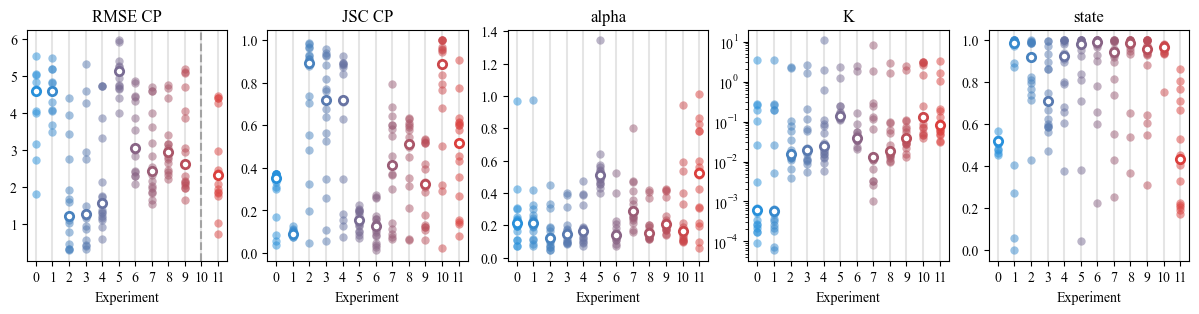

In [13]:
if task == 1:
    name_metrics = df.columns[1:6]
elif task == 2:
    name_metrics = df.columns[1:3]
fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

single_state = [10]

colors = cmap(np.linspace(0, 1, len(exps)))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)
    
    for exp in exps:
        axs[idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
        if exp in single_state and idxm == 0 and task == 1: 
            axs[idxm].axvline(exp, c =c_grey, ls = '--')
            continue

        metrics_plot = metrics[exp,:,idxm]

        if idxm == 0:
            metrics_plot = metrics_plot[metrics_plot != 0]
            
        axs[idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)

        axs[idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
    
plt.setp(axs[-2] if task == 1 else axs[-1], yscale = 'log')
plt.setp(axs, xlabel = 'Experiment', xticks = np.arange(len(exps)), xticklabels = exps);

#### Track 2, task 2

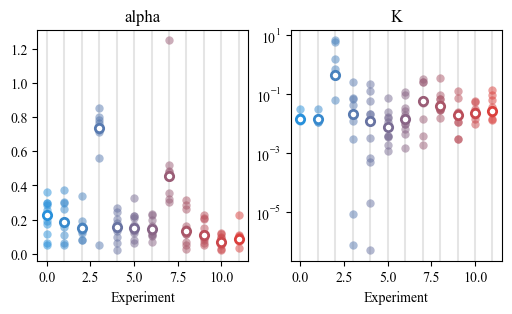

In [322]:
if task == 1:
    name_metrics = df.columns[1:6]
elif task == 2:
    name_metrics = df.columns[1:3]
fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

single_state = [10]

colors = cmap(np.linspace(0, 1, len(exps)))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)
    
    for exp in exps:
        axs[idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
        if exp in single_state and idxm == 0 and task == 1: 
            axs[idxm].axvline(exp, c =c_grey, ls = '--')
            continue

        metrics_plot = metrics[exp,:,idxm]

        if idxm == 0:
            metrics_plot = metrics_plot[metrics_plot != 0]
            
        axs[idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)

        axs[idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
    
plt.setp(axs[-2] if task == 1 else axs[-1], yscale = 'log')
plt.setp(axs, xlabel = 'Experiment');

# Analysis

Group 1: Confinment vs multi-state

Group 2: 'immobile_traps', 'confinement', 'dimerization', 'multi_state'

Group 3: 3-state multistate

Group 4: dimerization

Group 5: dimerization, multistate

Group 6: single very heterogeneous

Group 7: fast trapping

In [1105]:
groups = [[0,1],
          [2,3,4,5],
          [6], [7],
          [8, 9],
          [10], [11]]

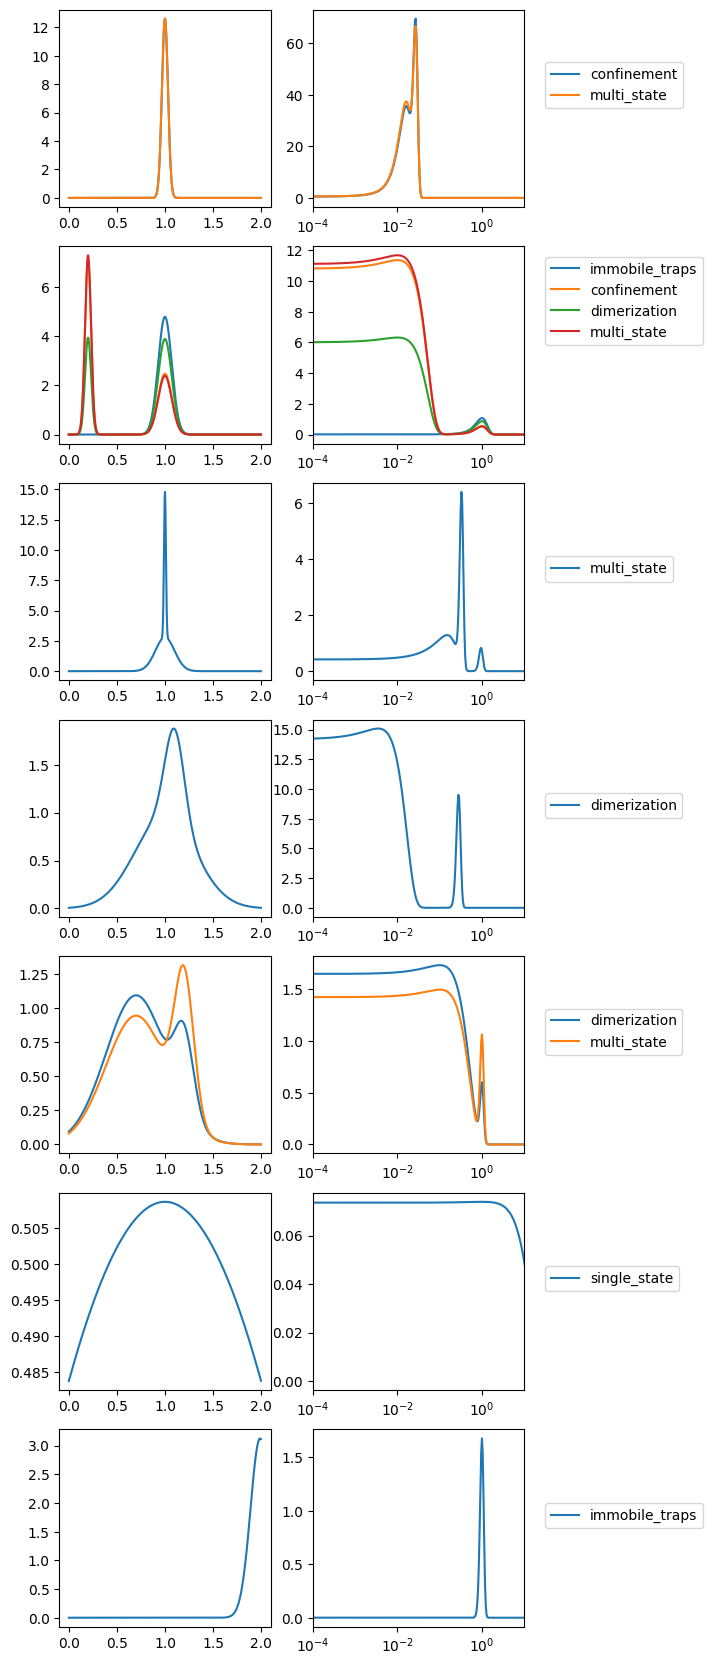

In [564]:
fig,axs = plt.subplots(len(groups), 2, figsize = (6,len(groups)*3))
track = 2
path = f'data/challenge_phase/reference_challenge_phase/track_{track}/'

for idx, group in enumerate(groups):
    for exp in group:
        path_file = os.path.join(path, f'exp_{exp}/ensemble_labels.txt')
        data = np.loadtxt(path_file, skiprows = 1, delimiter = ';')

        with open(path_file, 'r') as file:
           first_line = file.readline()
           model_type = first_line.split('model: ')[1].split(';')[0].strip()
            
        if model_type == 'immobile_traps':
            data = data[:,1:]
        
        _, _, dists = error_Ensemble_dataset(data, np.ones_like(data), return_distributions=True, size_support = 1000)
        true_a, true_D, _ , _ = dists

        # Define the support for the distributions
        x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                              models_phenom().bound_alpha[1], true_a.shape[0])
        x_D = np.logspace(np.log10(models_phenom().bound_D[0]), 
                          np.log10(models_phenom().bound_D[1]), true_D.shape[0]) 
        
        
        axs[idx,0].plot(x_alpha, true_a)
        axs[idx,1].semilogx(x_D, true_D, label = model_type)
        # else:
        #     axs[idx,0].plot(x_alpha[100:], true_a[100:], label = model_type)
        #     axs[idx,1].semilogx(x_D[100:], true_D[100:])
    axs[idx,1].legend(loc = (1.1,0.5))
    
plt.setp(axs[:,1], xlim = (1e-4, 1e1));   

## Exp 0 (failde)
> Boundaries were too far away and diffusion too slow...

In [1565]:
exp = 0; track = 2; task = 1

In [1566]:
tpops = []
ppops = []

num_teams = 5

df_ranking = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_single.csv')
letters = get_letter_from_teams(df_ranking.Team.values)


true_state_pops = np.zeros(len(models_phenom().lab_state))

true_conf_dist = np.array([])
true_free_dist = np.array([])

pred_state_pops, pred_conf_dist, pred_free_dist = [], [], []
print(exp)

for idxt, letter in enumerate(letters[:num_teams]):
    
    state_pops = np.zeros(len(models_phenom().lab_state))
    free_dist = np.array([])
    conf_dist = np.array([])
    for fov in range(num_fovs):    
        
        preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))   
        
        if idxt == 0:
            trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
        
        
        for idx in range(preds_fov.shape[0]):

            # Predicted pop
            cps = np.append(0, preds_fov.changepoints.loc[idx])
            seg_l = cps[1:]-cps[:-1]            
            states = preds_fov.states.loc[idx] 
            
            for l, s in zip(seg_l, states):
                state_pops[int(s)] += l

                if s == 1:
                    conf_dist = np.append(conf_dist, l)
                else:
                    free_dist = np.append(free_dist, l)
                    

            # True pop
            if idxt == 0:
                # Predicted pop
                cps = np.append(0, trues_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                states = trues_fov.states.loc[idx] 
                
                for l, s in zip(seg_l, states):
                    true_state_pops[int(s)] += l

                    if s == 1:
                        true_conf_dist = np.append(true_conf_dist, l)
                    else:
                        true_free_dist = np.append(true_free_dist, l)
                        

    pred_state_pops.append(state_pops)
    pred_conf_dist.append(conf_dist)
    pred_free_dist.append(free_dist) 
#     plt.bar(np.arange(4)+idxt*0.1-0.2, state_pops, width = 0.1)
# plt.bar(np.arange(4), true_state_pops, width = 0.5, facecolor = 'k', alpha = 0.3)
        

0


90.92366412213741 94.54201680672269


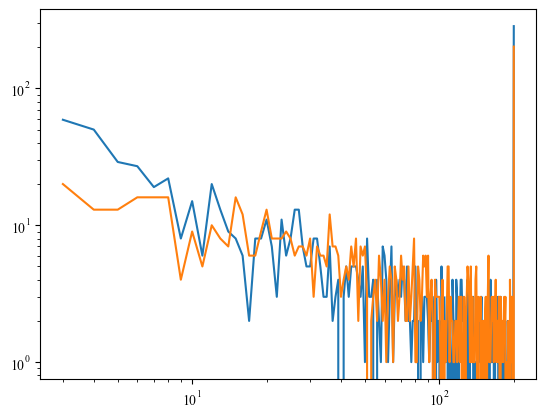

In [1567]:
free = np.bincount(true_free_dist.astype(int))
conf = np.bincount(true_conf_dist.astype(int))

plt.loglog(np.arange(3, len(free)), free[3:])
plt.plot(np.arange(3, len(conf)), conf[3:])

print(np.mean(true_free_dist), np.mean(true_conf_dist))

/home/gorka/miniconda3/envs/andi/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/gorka/miniconda3/envs/andi/lib/python3.10/site-packages/numpy/core/_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


[-0.3,
 1.3,
 Text(0, 0.5, 'Residence time'),
 Text(0, 0, 'Confined'),
 Text(1, 0, 'Free / Directed')]

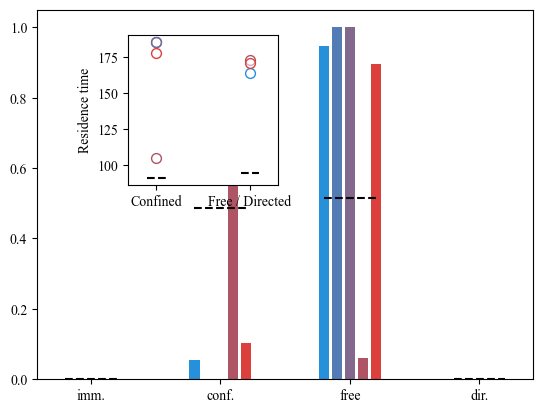

In [1568]:
fig, axs = plt.subplots()

colors = cmap(np.linspace(0, 1, num_teams))

         
for idxt, state_pops in enumerate(pred_state_pops):        
    axs.bar(np.arange(4)+idxt*0.1-(0.1*np.floor(num_teams/2)), state_pops/state_pops.sum(), width = 0.08, facecolor = colors[idxt])
    

for idxtp, tp in enumerate(true_state_pops/true_state_pops.sum()):
    axs.plot([idxtp-(0.1*np.floor(num_teams/2)), idxtp+(0.1*np.floor(num_teams/2))],
                   [tp, tp],
                   ls = '--', c = 'k')
# axs[idxe].bar(np.arange(4), tpops[idxe]/tpops[idxe].sum(), width = 0.8, facecolor = 'k', alpha = 0.3, zorder = -5)
plt.setp(axs, xticks = np.arange(4), xticklabels = ['imm.', 'conf.', 'free', 'dir.']);



axs_in = inset_axes(axs, width=1.5, height=1.5, bbox_to_anchor=(0.5, 0.95, 0, 0), bbox_transform=axs.transAxes) 

width = 0.1

axs_in.plot([-width, width], [np.mean(true_free_dist), np.mean(true_free_dist)], c = 'k', ls = '--')
axs_in.plot([1-width, 1+width], [np.mean(true_conf_dist), np.mean(true_conf_dist)], c = 'k', ls = '--')

for free_dist, conf_dist, c in zip(pred_free_dist, pred_conf_dist, colors):
    axs_in.scatter([0,1], [np.mean(free_dist), np.mean(conf_dist)], facecolor = (1,1,1,0.5), edgecolor = c, s = 50)

plt.setp(axs_in, xlim = [-0.3, 1.3], ylabel = 'Residence time',
        xticks = [0,1], xticklabels = ['Confined', 'Free / Directed'])


## Exp = 1 and 5 (failed)

> There was a proble with $M$ of exp 1 and 5 which makes the states to swap super fast.

1.4317673378076063 10.87248322147651
1.8046709129511678 9.713375796178344
2.160574412532637 3.9229765013054827
8.36860957342885 3.7121458808205796


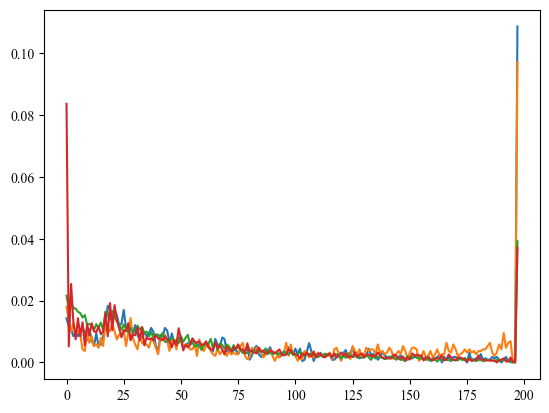

In [571]:
track = 2; task = 1
num_fovs = 30
for exp in [2,3,4,5]:

    lengths = []
    seg_lengths = np.array([])
    for fov in range(num_fovs):
        df = load_file_to_df(path_red(track, exp, fov))
        
        for cp in df.changepoints:
            cp = np.array([0]+cp)
            seg_l = cp[1:]-cp[:-1]
            seg_lengths = np.append(seg_lengths, seg_l)

    bc = np.bincount(seg_lengths.astype(int))
    print(bc[3]/np.sum(bc)*100, bc[-1]/np.sum(bc)*100)
    
    plt.plot(bc[3:]/np.sum(bc))

## Exp 10 (single state)

In [29]:
exp = 10

### MSD prediction

Getting the true dataframe for the whole experiment

In [30]:
# path_ref = lambda track, exp, fov: f'/home/gorka/github/andi_codalab_bundle/data/challenge_phase/reference_challenge_phase/track_{track}/exp_{exp}/traj_labs_fov_{fov}.txt'
track = 2

try:
    del df_true_exp
except:
    pass
    
for fov in range(num_fovs):
    
    trues_fov = load_file_to_df(path_ref(track, exp, fov))    
    trues_fov = trues_fov.sort_values('traj_idx')
    
    try:
        trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
        df_true_exp = pd.concat([df_true_exp, trues_fov]) 
    except:            
        df_true_exp = trues_fov
        print(fov)

0


Making MSD prediction dataframe

In [36]:
df_msd_preds = pd.DataFrame(columns = ['traj_idx', 'Ds', 'alphas', 'states', 'changepoints'])
path_traj = lambda exp, fov: f'/home/gorka/github/andi_codalab_bundle/data/challenge_phase/public_data_challenge_phase/track_2/exp_{exp}/trajs_fov_{fov}.csv'


for fov in range(num_fovs):
    
    df = pd.read_csv(path_traj(exp, fov))
    
    for idx in np.unique(df.traj_idx).astype(int):
        
        df_part = df.loc[df.traj_idx == idx]
    
        traj = np.vstack((df_part.x.values, df_part.y.values)).transpose()
        
        alpha = msd_analysis().get_exponent(traj[np.newaxis])
        D = msd_analysis().get_diff_coeff(traj[np.newaxis], t_lags=[1,2])
    
        df_msd_preds.loc[df_msd_preds.shape[0]] = [df_msd_preds.shape[0], D, alpha, [1], [traj.shape[0]]]
    

In [37]:
res = error_SingleTraj_dataset(df_msd_preds, df_true_exp)

  0%|          | 0/1556 [00:00<?, ?it/s]

Summary of metrics assesments:

Changepoint Metrics 
RMSE: 0 
Jaccard Index: 1 

Diffusion property metrics 
Metric anomalous exponent: 0.13349222960196377 
Metric diffusion coefficient: 0.47754513775511387 
Metric diffusive state: 0.0


In [38]:
ranking_exp = get_ranking_exp(track = track, task = 1, exp = exp)
metrics_exp = ranking_exp.iloc[:, :6].copy()
metrics_exp.loc[metrics_exp.shape[0]] = ['MSD']+list(res)

MSD for alpha

In [39]:
metrics_exp[['Team','alpha']].sort_values(by = 'alpha').reset_index(drop=True)

,Team,alpha
0,C,0.094937
1,E,0.102879
2,R,0.103177
3,H,0.111015
4,O,0.117746
5,I,0.130149
6,MSD,0.133492
7,Q,0.139643
8,N,0.161723
9,B,0.170146


MSD for K

In [40]:
metrics_exp[['Team','K']].sort_values(by = 'K').reset_index(drop=True)

,Team,K
0,I,0.037782
1,E,0.046713
2,C,0.046838
3,B,0.052963
4,R,0.069400
5,F,0.071460
6,N,0.088934
7,Q,0.120473
8,G,0.136689
9,D,0.248048


Calculating number of false positives

In [41]:
metrics_exp['FPR'] = None

for letter in metrics_exp.Team.values:

    if letter == 'MSD' or letter == 'J':
        continue

    num_trajs = 0
    total_cps_pred = np.array([])
    for fov in range(num_fovs):
    
        preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))    

        num_trajs += preds_fov.shape[0]
        
        cps_fov = np.concatenate(preds_fov.changepoints.values)

        
        
        total_cps_pred = np.append(total_cps_pred, cps_fov)

    FP = total_cps_pred.shape[0] - df_true_exp.shape[0]
    TN = df_true_exp.shape[0]
    
    metrics_exp.loc[metrics_exp.Team == letter, 'FPR'] = FP / (FP + TN)

In [42]:
metrics_exp

,Team,RMSE CP,JSC CP,alpha,K,state,FPR
0,I,0.0,1.000000,0.130149,0.037782,0.976864,0.0
1,E,0.0,1.000000,0.102879,0.046713,0.972365,0.0
2,C,0.0,1.000000,0.094937,0.046838,0.980077,0.0
3,R,0.0,0.835966,0.103177,0.069400,0.939589,0.147864
4,O,0.0,0.966794,0.117746,2.905968,0.932519,0.032338
5,Q,0.0,1.000000,0.139643,0.120473,0.978149,0.0
6,D,0.0,0.320171,0.331620,0.248048,0.973650,0.634656
7,N,0.0,0.952776,0.161723,0.088934,0.978792,0.045399
8,B,0.0,0.023853,0.170146,0.052963,0.965938,0.756304
9,F,0.0,0.767659,0.189970,0.071460,0.968509,0.203685


In [43]:
metrics_exp.to_csv('figures/df_single_state.csv')

In [49]:
metrics_exp.iloc[-1].alpha

0.13349222960196377

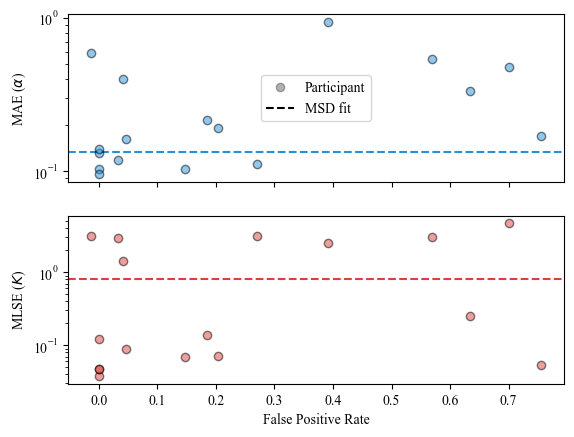

In [1585]:
metrics_exp.to_csv('figures/df_single_state.csv')

fig, axs = plt.subplots(2, 1)

axs[0].scatter(metrics_exp.FPR, metrics_exp.alpha, c = c_main, alpha = 0.5, edgecolor = 'k')
axs[0].axhline(metrics_exp.iloc[-1].alpha, c = c_main, ls = '--', zorder = -1)

axs[1].scatter(metrics_exp.FPR, metrics_exp.K, c = c_comp, alpha = 0.5, edgecolor = 'k')
axs[1].axhline(metrics_exp.iloc[-1].K, c = c_comp, ls = '--', zorder = -1)

plt.setp(axs[0], xticklabels = [], ylabel = r'MAE ($\alpha$)');
plt.setp(axs[1], xlabel = 'False Positive Rate', ylabel = r'MLSE ($K$)');


# Create handles for the legend
circle = mlines.Line2D([], [], color='k', alpha = 0.3, marker='o', linestyle='None', label='Participant')  # Circle marker
line = mlines.Line2D([], [], color='k', linestyle='--', label='MSD fit')  # Line

# Add legend to the plot
axs[0].legend(handles=[circle, line])

plt.setp(axs, yscale = 'log')

plt.show()


### Checking new dataset

In [27]:
df_msd_preds = pd.DataFrame(columns = ['traj_idx', 'Ds', 'alphas', 'states', 'changepoints'])


for fov in range(num_fovs):
    
    df = pd.read_csv(f'/home/gorka/github/andi_datasets/source_nbs/tutorials/andi_benchmark/track_2/exp_8/trajs_fov_{fov}.csv')
    
    for idx in np.unique(df.traj_idx).astype(int):
        
        df_part = df.loc[df.traj_idx == idx]
    
        traj = np.vstack((df_part.x.values, df_part.y.values)).transpose()
        
        alpha = msd_analysis().get_exponent(traj[np.newaxis])
        D = msd_analysis().get_diff_coeff(traj[np.newaxis], t_lags = [1,2])
    
        df_msd_preds.loc[df_msd_preds.shape[0]] = [df_msd_preds.shape[0], D, alpha, [1], [traj.shape[0]]]
    

In [21]:
try:
    del df_true_exp
except:
    pass
    
for fov in range(num_fovs):
    
    trues_fov = load_file_to_df(f'/home/gorka/github/andi_datasets/source_nbs/tutorials/andi_benchmark/track_2/exp_8/traj_labs_fov_{fov}.txt') 
    trues_fov = trues_fov.sort_values('traj_idx')
    
    try:
        trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
        df_true_exp = pd.concat([df_true_exp, trues_fov]) 
    except:            
        df_true_exp = trues_fov
        print(fov)

0


In [28]:
res = error_SingleTraj_dataset(df_msd_preds, df_true_exp)

  0%|          | 0/1524 [00:00<?, ?it/s]

Summary of metrics assesments:

Changepoint Metrics 
RMSE: 0 
Jaccard Index: 1 

Diffusion property metrics 
Metric anomalous exponent: 0.1446700924734244 
Metric diffusion coefficient: 0.5293662957439976 
Metric diffusive state: 0.0


In [99]:
res = error_SingleTraj_dataset(df_msd_preds, df_true_exp)

  0%|          | 0/1556 [00:00<?, ?it/s]

Summary of metrics assesments:

Changepoint Metrics 
RMSE: 0 
Jaccard Index: 1 

Diffusion property metrics 
Metric anomalous exponent: 0.13349222960196377 
Metric diffusion coefficient: 0.8051026072363047 
Metric diffusive state: 0.0


### Metrics vs. $\alpha$, $K$

In [962]:
def condition_alpha(df, alpha_range, **kwargs):
    '''
    Considers that df has two columns 'alphas' and 'traj_idx' and returns the values
    of 'traj_idx' where alpha_range[0] < alphas < alpha_range[1]
    '''
    
    return df.loc[df['alphas'].apply(np.squeeze).between(alpha_range[0], alpha_range[1], inclusive='right'), 'traj_idx'].values.astype(int)

In [977]:
alpha_ranges = np.vstack((np.arange(0,2,0.4), np.arange(0,2,0.4)+0.4)).transpose()

In [978]:
alpha_ranges

array([[0. , 0.4],
       [0.4, 0.8],
       [0.8, 1.2],
       [1.2, 1.6],
       [1.6, 2. ]])

In [972]:
alpha_ranges = np.array([[0,0.75],
                [0.75, 1.25],
                [1.25, 2]
               ])
alpha_ranges.shape


(3, 2)

In [979]:
alpha_ranges = np.vstack((np.arange(0,2,0.4), np.arange(0,2,0.4)+0.4)).transpose()

track = 2; task = 1; exp = 10;
df_ranking = get_ranking_exp(track = track, task = task, exp = exp)
letters = df_ranking.Team.values

metrics_ar = np.zeros((len(alpha_ranges), 5, len(letters)))

for idxc, alpha_range in enumerate(alpha_ranges):
    metrics_ar[idxc] = metrics_with_codition_st(letters_teams = letters, condition=condition_alpha, exp_single_state = True, alpha_range = alpha_range)

np.save('data/challenge_phase/analysis_data/metrics_vs_alpha_ranges_exp10.npy', metrics_ar)

[10]


  0%|          | 0/1 [00:00<?, ?it/s]

[10]


  0%|          | 0/1 [00:00<?, ?it/s]

[10]


  0%|          | 0/1 [00:00<?, ?it/s]

[10]


  0%|          | 0/1 [00:00<?, ?it/s]

[10]


  0%|          | 0/1 [00:00<?, ?it/s]

In [966]:
metrics_ar[:,2,:].mean(-1)

array([0.25916205, 0.20758967, 0.30165901])

In [910]:
track = 2; task = 1; exp = 10;
df_ranking = get_ranking_exp(track = track, task = task, exp = exp)

alphas = []

try:
    del df_true_exp
except:
    pass

alphas_preds = []
Ds_preds = []
for idxl, letter in enumerate(tqdm(df_ranking.Team.values)):

    try:
        del df_pred_exp
    except:
        pass

    for fov in range(num_fovs):

        if idxl == 0:
            trues_fov = load_file_to_df(path_ref(track, exp, fov)) 

            # Full experiment dataframe
            try:
                trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
                df_true_exp = pd.concat([df_true_exp, trues_fov]) 
            except:            
                df_true_exp = trues_fov              


        preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))   

        # Full experiment dataframe
        try:
            preds_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
            df_pred_exp = pd.concat([df_pred_exp, preds_fov]) 
        except:            
            df_pred_exp = preds_fov 
        
    alphas_preds.append(df_pred_exp['alphas'].apply(np.squeeze).values)
    Ds_preds.append(df_pred_exp['Ds'].apply(np.squeeze).values)

faulty_team = int(np.argwhere(np.array([a.shape for a in alphas_preds]).flatten() != 1556))
df_ranking = df_ranking.drop(index=faulty_team)
alphas_preds.pop(faulty_team)
Ds_preds.pop(faulty_team)

alphas_preds = np.array(alphas_preds)
Ds_preds = np.array(Ds_preds)

alphas_trues = df_true_exp['alphas'].apply(np.squeeze).values
Ds_trues = df_true_exp['Ds'].apply(np.squeeze).values

  0%|          | 0/17 [00:00<?, ?it/s]

In [918]:
alphas_preds.shape

(16, 1556)

In [ ]:
import metr

In [926]:
true_a.shape

(493,)

In [939]:
alphas_preds[3][idx_range].shape

(493,)

In [924]:
alpha_ranges = [[0,0.75],
                [0.75, 1.25],
                [1.25, 2]
               ]
mse_range = np.zeros((alphas_preds.shape[0], len(alpha_ranges)))
for idxa, ar in enumerate(alpha_ranges):
    idx_range = np.argwhere((alphas_trues >= ar[0]) & (alphas_trues < ar[1])).flatten()
    true_a = alphas_trues[idx_range]

    for idxp, pred_a in enumerate(alphas_preds):
        pred_a = pred_a[idx_range]

        mse_range[idxp, idxa] = andi_utils.metric_anomalous_exponent(gt = true_a, pred = pred_a)

ValueError: operands could not be broadcast together with shapes (2,) (5,) 

## Exps 2,3,4

In [9]:
track = 2; task = 1;
exps = [2,3,4]

track_str = 'videos' if track == 1 else 'trajs'
task_str = 'single' if task == 1 else 'ens'
df_leaderboard = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv')
global_rank = df_leaderboard['Global rank'].values

ranks = []
metrics = []
for exp in exps:
    df_ranking = get_ranking_exp(track = track, task = task, exp = exp)
    ranks.append(df_ranking['Global Rank'].values)

    metrics.append(df_ranking.iloc[:, 1:6].values)

ranks = np.array(ranks)
metrics = np.array(metrics)

# Deleting far_naz from metrics
ranks = ranks[:,:-1]
metrics = metrics[:,:-1]
global_rank = global_rank[:-1]

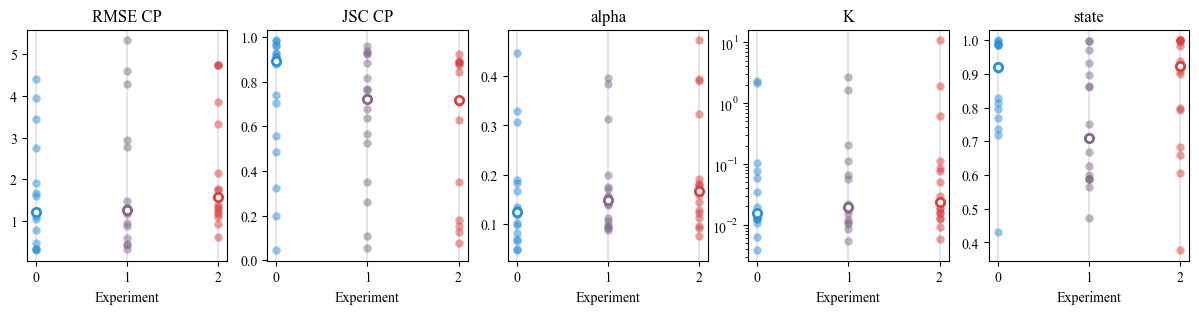

In [10]:
if task == 1:
    name_metrics = df_ranking.columns[1:6]
elif task == 2:
    name_metrics = df_ranking.columns[1:3]
fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

single_state = [10]

colors = cmap(np.linspace(0, 1, len(exps)))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)
    
    for exp, _ in enumerate(exps):
        axs[idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
        if exp in single_state and idxm == 0 and task == 1: 
            axs[idxm].axvline(exp, c =c_grey, ls = '--')
            continue

        metrics_plot = metrics[exp,:,idxm]

        if idxm == 0:
            metrics_plot = metrics_plot[metrics_plot != 0]
            
        axs[idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)

        axs[idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
    
plt.setp(axs[-2] if task == 1 else axs[-1], yscale = 'log')
plt.setp(axs, xlabel = 'Experiment');

Checking state classification

In [11]:
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')
dict_inv = dict((v,k) for k,v in dict_mapping.items())
letters = [dict_inv[key] for key in teams] 

NameError: name 'teams' is not defined

In [811]:
df_ranking

,Team,RMSE CP,JSC CP,alpha,K,state,RMSE CP rank,JSC CP rank,alpha rank,K rank,state rank,MRR,Global Rank
0,I,1.173427,0.890655,0.110932,0.005948,1.000000,4,16,4,1,1,0.512500,1
1,E,1.292005,0.890325,0.127856,0.015481,1.000000,6,15,6,5,1,0.320000,5
2,C,0.606737,0.883139,0.095420,0.050469,0.999934,1,14,3,10,5,0.340952,4
3,R,0.920022,0.873738,0.121742,0.009145,0.684343,2,13,5,2,14,0.269670,6
4,O,1.225415,0.893698,0.143501,0.029449,0.937525,5,17,7,9,8,0.127558,10
5,Q,2.151728,0.842358,0.090633,0.012824,0.659238,11,12,2,4,15,0.198182,8
6,D,1.342880,0.923875,0.074147,0.012226,1.000000,7,18,1,3,1,0.506349,2
7,N,1.108232,0.711199,0.175655,0.018769,0.898667,3,9,9,8,11,0.154293,9
8,B,4.734837,0.074961,0.323612,0.086724,1.000000,14,2,13,12,1,0.346337,3
9,F,1.384066,0.720068,0.158348,0.018113,0.799718,8,11,8,7,12,0.113420,13


In [12]:
tpops = []
ppops = []

num_teams = 5
for exp in exps:

    df_ranking = pd.read_csv(path_leaderboard('trajs', 'single')) #get_ranking_exp(track = track, task = task, exp = exp)
    letters = get_letter_from_teams(df_ranking.sort_values(by = 'Global rank').Team.values[:num_teams])
    
    true_state_pops = np.zeros(len(models_phenom().lab_state))
    pred_state_pops = []
    print(exp)
    # for idxt, team in enumerate(df_leaderboard.Team.values[:num_teams]): # Here we are taking top 5 of 
        # letter = dict_inv[team]
    for idxt, letter in enumerate(letters):

        
        state_pops = np.zeros(len(models_phenom().lab_state))
        
        for fov in range(num_fovs):    
            
            preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))   
            
            if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
            
            
            for idx in range(preds_fov.shape[0]):
    
                # Predicted pop
                cps = np.append(0, preds_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                states = preds_fov.states.loc[idx] 
                for l, s in zip(seg_l, states):
                    state_pops[int(s)] += l
    
                # True pop
                if idxt == 0:
                    # Predicted pop
                    cps = np.append(0, trues_fov.changepoints.loc[idx])
                    seg_l = cps[1:]-cps[:-1]            
                    states = trues_fov.states.loc[idx] 
                    for l, s in zip(seg_l, states):
                        true_state_pops[int(s)] += l
    
        pred_state_pops.append(state_pops)
    tpops.append(true_state_pops)
    ppops.append(pred_state_pops)
#     plt.bar(np.arange(4)+idxt*0.1-0.2, state_pops, width = 0.1)
# plt.bar(np.arange(4), true_state_pops, width = 0.5, facecolor = 'k', alpha = 0.3)
        

2
3



KeyboardInterrupt



In [112]:
np.save('classification_models_true_pops.npy', tpops)
np.save('classification_models_pred_pops.npy', ppops)

In [ ]:
np.save('classification_models_true_pops_all_exps.npy', tpops)
np.save('classification_models_pred_pops_all_exps.npy', ppops)

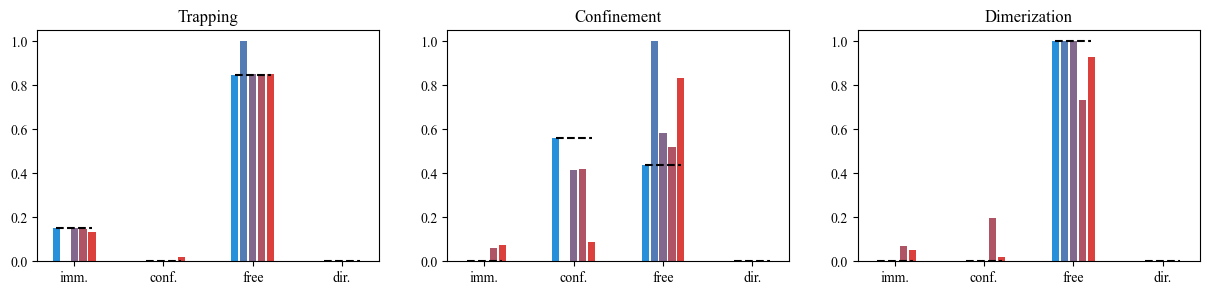

In [113]:

fig, axs = plt.subplots(1, len(exps), figsize = (5*len(exps), 3))

exps_name = ['Trapping', 'Confinement', 'Dimerization']

colors = cmap(np.linspace(0, 1, num_teams))


for idxe in range(len(exps)):
    
    axs[idxe].set_title(exps_name[idxe])             
    for idxt, state_pops in enumerate(ppops[idxe]):        
        axs[idxe].bar(np.arange(4)+idxt*0.1-(0.1*np.floor(num_teams/2)), state_pops/state_pops.sum(), width = 0.08, facecolor = colors[idxt])
        

    for idxtp, tp in enumerate(tpops[idxe]/tpops[idxe].sum()):
        axs[idxe].plot([idxtp-(0.1*np.floor(num_teams/2)), idxtp+(0.1*np.floor(num_teams/2))],
                       [tp, tp],
                       ls = '--', c = 'k')
    # axs[idxe].bar(np.arange(4), tpops[idxe]/tpops[idxe].sum(), width = 0.8, facecolor = 'k', alpha = 0.3, zorder = -5)


plt.setp(axs, xticks = np.arange(4), xticklabels = ['imm.', 'conf.', 'free', 'dir.']);


This is the same but ranking w.r.t. general leaderboard

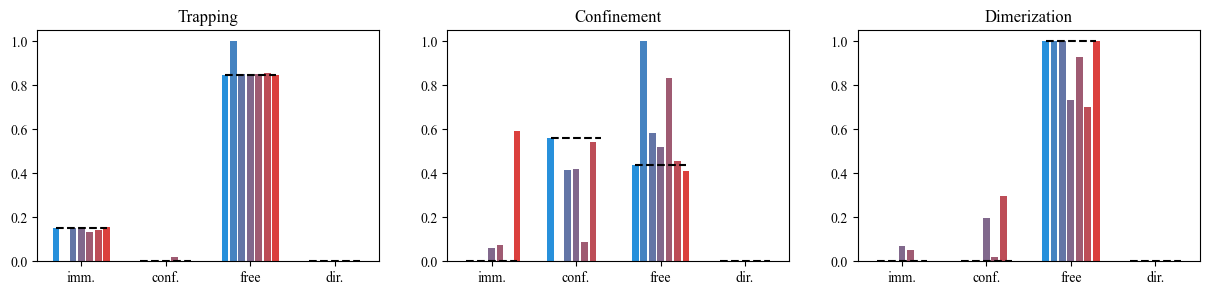

In [654]:
fig, axs = plt.subplots(1, len(exps), figsize = (5*len(exps), 3))

exps_name = ['Trapping', 'Confinement', 'Dimerization']

colors = cmap(np.linspace(0, 1, num_teams))


for idxe in range(len(exps)):
    
    axs[idxe].set_title(exps_name[idxe])             
    for idxt, state_pops in enumerate(ppops[idxe]):        
        axs[idxe].bar(np.arange(4)+idxt*0.1-(0.1*np.floor(num_teams/2)), state_pops/state_pops.sum(), width = 0.08, facecolor = colors[idxt])

    for idxtp, tp in enumerate(tpops[idxe]/tpops[idxe].sum()):
        axs[idxe].plot([idxtp-(0.1*np.floor(num_teams/2)), idxtp+(0.1*np.floor(num_teams/2))],
                       [tp, tp],
                       ls = '--', c = 'k')
    # axs[idxe].bar(np.arange(4), tpops[idxe]/tpops[idxe].sum(), width = 0.8, facecolor = 'k', alpha = 0.3, zorder = -5)


plt.setp(axs, xticks = np.arange(4), xticklabels = ['imm.', 'conf.', 'free', 'dir.']);


Checking the diffusion properties of the predicted phases Trapping and confinement

In [889]:
df_ranking_ens = get_ranking_exp(track = track, task = 2, exp = exp).sort_values(by = 'Global Rank')
df_ranking_ens.Team[1]

'M'

In [919]:
df_ranking.sort_values(by = 'Global Rank').Team.values[:num_teams]

array(['D', 'I', 'C', 'E', 'R'], dtype=object)

In [1590]:
df_ranking = pd.read_csv(path_leaderboard('trajs', 'single'))

In [1593]:
dict_mapping

{'A': 'AIntgonnawork',
 'B': 'EmetBrown',
 'C': 'HNU',
 'D': 'Unfriendly AI',
 'E': 'SPT-HIT',
 'F': 'BIOMED-UCA',
 'G': 'KNU-ON',
 'H': 'Nanoninjas',
 'I': 'UCL SAM',
 'J': 'far_naz',
 'K': 'ICSO UPV',
 'L': 'HSC AI',
 'M': 'DeepSPT',
 'N': 'KCL',
 'O': 'bjyong',
 'P': 'D.AnDi',
 'Q': 'SU-FIONA',
 'R': 'M3'}

In [1594]:
team = ['UCL SAM']
get_letter_from_teams(team)

['I']

In [1601]:

num_teams = 5

TA_f, TA_p = [], []
PA_f, PA_p, PE = [], [], []
LS, LE = [], []

track_str = 'videos' if track == 1 else 'trajs'
task_str = 'single' if task == 1 else 'ens'


df_ranking = pd.read_csv(path_leaderboard('trajs', 'single'))
df_ranking_ens = pd.read_csv(path_leaderboard('trajs', 'ens'))

for exp in exps:
    print(exp)
    true_alphas_f = np.array([])
    true_alphas_p = np.array([])
    
    pred_alphas_f = []
    pred_alphas_p = []
    pred_ens = []

    letters_s = []
    letters_e = []


    LS.append(df_ranking.Team.values[:num_teams])
    LE.append(df_ranking_ens.Team.values[:num_teams])    
    
    for idxt, team in enumerate(df_ranking.Team.values[:num_teams]):
        letter = get_letter_from_teams([team])[0]
        
        
    
    # for idxt, team in enumerate(df_leaderboard.Team.values[:num_teams]):    
    #     letter = dict_inv[team]
        
        team_alphas_f = np.array([])
        team_alphas_p = np.array([])
        team_pred_ens = []
        
        for fov in range(num_fovs):    

            ############# Single traj #############
            preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))             
            
            if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
              
            for idx in range(preds_fov.shape[0]):
    
                # Predicted pop
                cps = np.append(0, preds_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                alphas = np.array(preds_fov.alphas.loc[idx])
                states = np.array(preds_fov.states.loc[idx])
    
                
                seg_free = seg_l#[states == 2]
                alpha_free = alphas#[states == 2]
                for l, a in zip(seg_free, alpha_free):
                    team_alphas_f = np.append(team_alphas_f, np.ones(int(l))*a)
    
                seg_p = seg_l[states != 2]
                alpha_p = alphas[states != 2]
                for l, a in zip(seg_p, alpha_p):
                    team_alphas_p = np.append(team_alphas_p, np.ones(int(l))*a)
    
                # True pop
                if idxt == 0:
                    # Predicted pop
                    cps = np.append(0, trues_fov.changepoints.loc[idx])
                    seg_l = cps[1:]-cps[:-1]          
                    alphas = np.array(trues_fov.alphas.loc[idx])
                    states = np.array(trues_fov.states.loc[idx])
    
                    seg_free = seg_l#[states == 2]
                    alpha_free = alphas#[states == 2]
                    for l, a in zip(seg_free, alpha_free):
                        true_alphas_f = np.append(true_alphas_f, np.ones(int(l))*a)
        
                    seg_p = seg_l[states != 2]
                    alpha_p = alphas[states != 2]
                    for l, a in zip(seg_p, alpha_p):
                        true_alphas_p = np.append(true_alphas_p, np.ones(int(l))*a)

        pred_alphas_f.append(team_alphas_f)
        pred_alphas_p.append(team_alphas_p)
        
        # Ensemble
        letter_ens = get_letter_from_teams([df_ranking_ens.Team[idxt]])[0]
        path_pred_ens = f'data/challenge_phase/submissions_post15/{letter_ens}/track_{track}/exp_{exp}/ensemble_labels.txt'
        try:
            pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))
        except:
            print(letter_ens, dict_mapping[letter_ens])
    
                    
        

    TA_f.append(true_alphas_f)
    TA_p.append(true_alphas_p)
    PA_f.append(pred_alphas_f)
    PA_p.append(pred_alphas_p)
    PE.append(pred_ens)
        

2


/tmp/ipykernel_130672/2716334611.py:94: UserWarning: loadtxt: input contained no data: "data/challenge_phase/submissions_post15/C/track_2/exp_2/ensemble_labels.txt"
  pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))


R M3
3


/tmp/ipykernel_130672/2716334611.py:94: UserWarning: loadtxt: input contained no data: "data/challenge_phase/submissions_post15/C/track_2/exp_3/ensemble_labels.txt"
  pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))


R M3
4


...

R M3
10


/tmp/ipykernel_130672/2716334611.py:94: UserWarning: loadtxt: input contained no data: "data/challenge_phase/submissions_post15/C/track_2/exp_10/ensemble_labels.txt"
  pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))


R M3
11


/tmp/ipykernel_130672/2716334611.py:94: UserWarning: loadtxt: input contained no data: "data/challenge_phase/submissions_post15/C/track_2/exp_11/ensemble_labels.txt"
  pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))


R M3


In [1602]:
from scipy.stats import gaussian_kde
from andi_datasets.utils_challenge import multimode_dist

Ds_g2 = np.array([[1, 0.1],
                  [0.01, 0.001]])
alphas_g2 = np.array([[1, 0.005],
                      [0.2, 0.001]])

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

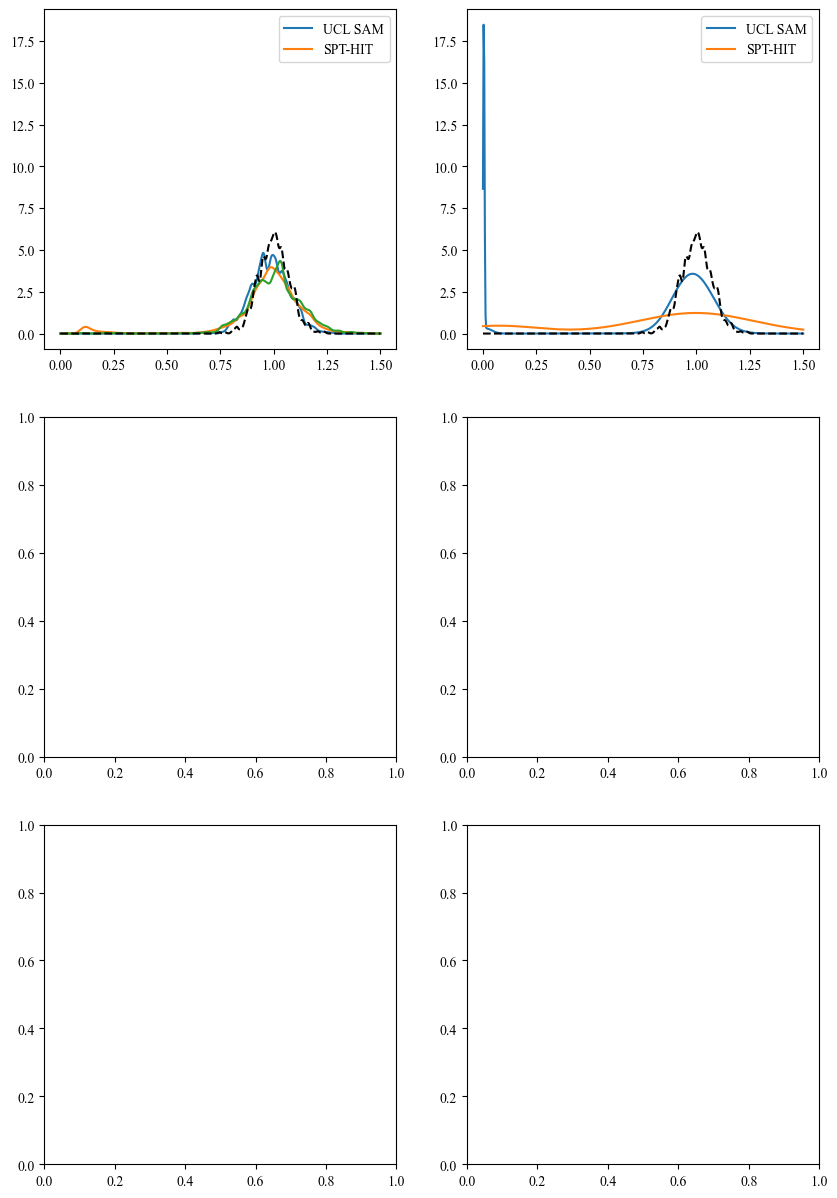

In [1603]:

colors = cmap(np.linspace(0, 1, num_teams))

fig, ax = plt.subplots(3,2, figsize = (2*5, 3*5))
x_values = np.linspace(0, 1.5, 500)

for idxe, (pred_alphas_f, pred_alphas_p, pred_ens, lss, les) in enumerate(zip(PA_f, PA_p, PE, LS, LE)):
    
    
    for idxp, (paf, pap, pe, ls, le) in enumerate(zip(pred_alphas_f, pred_alphas_p, pred_ens, lss, les)):

        paf = paf[paf>0.1]        
        kde = gaussian_kde(paf)
        kde_values = kde(x_values)        
        
        ax[idxe,0].plot(x_values, kde_values, label = ls)

        if idxp == 0:
            paf = TA_f[idxe]
            paf = paf[paf>0.1]        
            kde = gaussian_kde(paf)
            kde_values = kde(x_values)        
            
            ax[idxe,0].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')
            ax[idxe,1].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')

        
        dist = multimode_dist(pe[:2,:].transpose(), pe[-1,:], (0,2), x_values)    
        ax[idxe,1].plot(x_values, dist, label = le)

        ax[idxe,0].legend()
        ax[idxe,1].legend()

        ylim0 = ax[idxe,0].get_ylim()
        ylim1 = ax[idxe,1].get_ylim()
        
        plt.setp(ax[idxe], ylim = (min(ylim0[0],ylim1[0]), max(ylim0[1],ylim1[1])))


            

        # if idxe != 0:
        #     pap = pap[pap<2]        
        #     kde = gaussian_kde(pap)
        #     x_values = np.linspace(min(pap), max(pap), 100)
        #     kde_values = kde(x_values)  
    
        #     ax[idxe].plot(x_values, kde_values, c = colors_r[idxp])
        
plt.setp(ax[0,0], title = 'Gaussian KDE to Single trajs')
plt.setp(ax[0,1], title = 'Ensemble prediction')

# plt.setp(ax, ylim = (0,5))

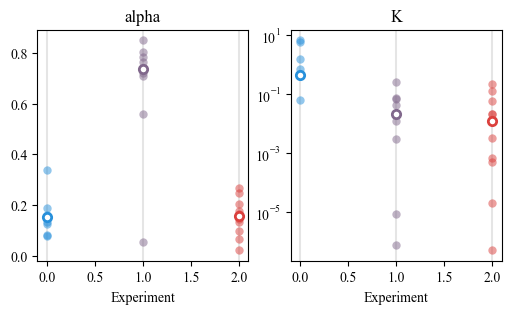

In [531]:
if task == 1:
    name_metrics = df.columns[1:6]
elif task == 2:
    name_metrics = df.columns[1:3]
fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

single_state = [10]

colors = cmap(np.linspace(0, 1, len(exps)))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)
    
    for exp, _ in enumerate(exps):
        axs[idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
        if exp in single_state and idxm == 0 and task == 1: 
            axs[idxm].axvline(exp, c =c_grey, ls = '--')
            continue

        metrics_plot = metrics[exp,:,idxm]

        if idxm == 0:
            metrics_plot = metrics_plot[metrics_plot != 0]
            
        axs[idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)

        axs[idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
    
plt.setp(axs[-2] if task == 1 else axs[-1], yscale = 'log')
plt.setp(axs, xlabel = 'Experiment');

## Exp 6

In [950]:
exp = 6

In [951]:
get_ranking_exp(track = track, task = 1, exp = exp)#.sort_values(by = 'JSC CP rank')

,Team,RMSE CP,JSC CP,alpha,K,state,RMSE CP rank,JSC CP rank,alpha rank,K rank,state rank,MRR,Global Rank
0,I,2.450043,0.256415,0.073402,0.020780,1.000000,5,4,1,1,1,0.690000,1
1,E,2.306319,0.098668,0.134296,0.023612,1.000000,3,11,8,2,1,0.409848,3
2,C,2.092457,0.046173,0.136758,0.045356,1.000000,1,14,9,10,1,0.456508,2
3,R,3.050090,0.272262,0.111049,0.034590,0.600806,8,2,4,5,16,0.227500,10
4,O,2.838566,0.160359,0.159046,0.087488,0.900483,6,7,12,13,12,0.110623,14
5,Q,3.053781,0.038195,0.133460,0.035462,1.000000,9,15,7,6,1,0.297460,6
6,D,4.328334,0.160933,0.085373,0.054414,1.000000,12,6,2,11,1,0.368182,4
7,N,2.303340,0.085594,0.122828,0.036077,0.929786,2,12,6,7,11,0.196753,11
8,B,4.454735,0.108807,0.142688,0.039270,1.000000,14,10,10,8,1,0.279286,8
9,F,3.010832,0.142894,0.205514,0.034549,0.965411,7,8,14,4,10,0.137857,13


In [ ]:
p12 = 0.024; p13 = 0.03; 
p11 = 1-p12-p13
p21 = 0.016; p23 = 0.064
p22 = 1-p21-p23
p31 = 0.037; p32 = 0.140
p33 = 1-p31-p32

M_g3 =  np.array([[p11, p12, p13],
               [p21, p22, p23],
               [p31, p32, p33],
              ])

Ds_g3 = np.array([[0.15, 0.01],
               [0.33, 0.001],
               [0.95, 0.01]])
alphas_g3 = np.array([[1, 0.0001],
                      [1, 0.01],
                      [1, 0.01]])

In [963]:
all_cp = np.array([])
for fov in range(num_fovs):    

    ############# Single traj #############
    preds_fov = load_file_to_df(path_pred('I', track, exp,fov))                
      
    for idx in range(preds_fov.shape[0]):

        # Predicted pop
        cps = np.append(0, preds_fov.changepoints.loc[idx])
        all_cp = np.append(all_cp, cps[1:]-cps[:-1])
bc_p = np.bincount(all_cp.astype(int))

In [ ]:
track = 2; task = 1
num_fovs = 30


    lengths = []
    seg_lengths = np.array([])
    for fov in range(num_fovs):
        df = load_file_to_df(path_data(track, exp, fov))
        
        for cp in df.changepoints:
            cp = np.array([0]+cp)
            seg_l = cp[1:]-cp[:-1]
            seg_lengths = np.append(seg_lengths, seg_l)

    bc = np.bincount(seg_lengths.astype(int))
    # print(bc[3]/np.sum(bc)*100, bc[-1]/np.sum(bc)*100)
    

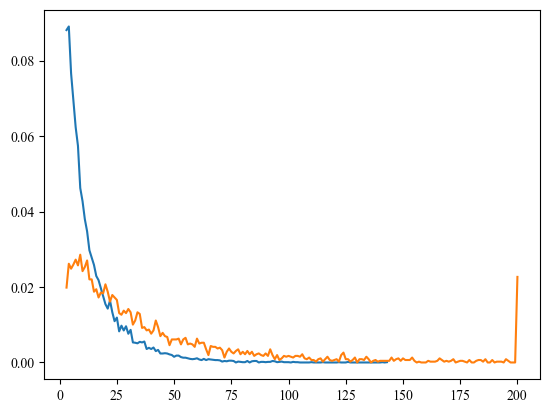

In [970]:
plt.plot(np.arange(3, max(seg_lengths)+1), bc[3:]/np.sum(bc))
plt.plot(np.arange(3, max(all_cp)+1), bc_p[3:]/np.sum(bc_p))

In [ ]:
from andi_datasets.utils_challenge import changepoint_assignment

exp = 6
df_pred = load_file_to_df(path_pred('I', track, exp,fov)) 
df_true = load_file_to_df(path_data(track, exp, fov))

ensemble_pred_cp = []
ensemble_true_cp = []
for t_idx in df_true['traj_idx'].values:
    
    traj_trues = df_true.loc[df_true.traj_idx == t_idx]
    traj_preds = df_pred.loc[df_pred.traj_idx == t_idx]

    preds_cp = np.array(traj_preds.changepoints.values[0]).astype(int)
    trues_cp = np.array(traj_trues.changepoints.values[0]).astype(int)

    print(t_idx)
    cp = np.append(0, trues_cp)
    seg_l = cp[1:]-cp[:-1]
    print(seg_l)
    cp = np.append(0, preds_cp)
    seg_l = cp[1:]-cp[:-1]
    print(seg_l, '\n')
    

    ensemble_pred_cp.append(preds_cp[:-1])
    ensemble_true_cp.append(trues_cp[:-1])

    
    
    
    assignment, _ = changepoint_assignment(trues_cp[:-1], preds_cp[:-1])
    assignment = np.array(assignment)
    # print(assignment)
    # break
    # rmse_CP, JI = ensemble_changepoint_error(ensemble_true_cp, ensemble_pred_cp, threshold = threshold_cp)

### Diffusion props

In [1044]:

num_teams = 5
exp = 6

true_alphas = np.array([])
true_ds = np.array([])

pred_alphas = []
pred_ds = []
pred_ens = []

letters_s = []
letters_e = []

df_ranking = get_ranking_exp(track = track, task = 1, exp = exp).sort_values(by = 'Global Rank')
df_ranking_ens = get_ranking_exp(track = track, task = 2, exp = exp).sort_values(by = 'Global Rank')

# LS.append(df_ranking.Team.values[:num_teams])
# LE.append(df_ranking_ens.Team.values[:num_teams])  
try:
    del trues_exp
    print('nice')
except:
    pass

for idxt, letter in enumerate(df_ranking.Team.values[:num_teams]):
    

# for idxt, team in enumerate(df_leaderboard.Team.values[:num_teams]):    
#     letter = dict_inv[team]
    
    team_alphas = np.array([])
    team_ds = np.array([])
    team_pred_ens = []
    
    for fov in range(num_fovs):    

        ############# Single traj #############
        preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))             
        
        if idxt == 0:
            trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
            trues_fov['seg_l'] = None
           
                
          
        for idx in range(preds_fov.shape[0]):

            # Predicted pop
            cps = np.append(0, preds_fov.changepoints.loc[idx])
            seg_l = cps[1:]-cps[:-1]            
            alphas = np.array(preds_fov.alphas.loc[idx])
            ds = np.array(preds_fov.Ds.loc[idx])
            states = np.array(preds_fov.states.loc[idx])
        
            for l, a, d in zip(seg_l, alphas, ds):
                team_alphas = np.append(team_alphas, np.ones(int(l))*a)
                team_ds = np.append(team_ds, np.ones(int(l))*d)


            # True pop
            if idxt == 0:
                # Predicted pop
                cps = np.append(0, trues_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]          
                alphas = np.array(trues_fov.alphas.loc[idx])
                ds = np.array(trues_fov.Ds.loc[idx])
                states = np.array(trues_fov.states.loc[idx])
                
                for l, a, d in zip(seg_l, alphas, ds):
                    true_alphas = np.append(true_alphas, np.ones(int(l))*a)                    
                    true_ds = np.append(true_ds, np.ones(int(l))*d)

                trues_fov.seg_l.loc[idx] = seg_l
        
        try:
            trues_exp = pd.concat([trues_exp, trues_fov], ignore_index=True)
        except:
            trues_exp = trues_fov


    pred_alphas.append(team_alphas)
    pred_ds.append(team_ds)
    
    # Ensemble
    letter_ens = df_ranking_ens.Team[idxt]
    path_pred_ens = f'data/challenge_phase/submissions_post15/{letter_ens}/track_{track}/exp_{exp}/ensemble_labels.txt'
    try:
        pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))
    except:
        print(letter_ens, dict_mapping[letter_ens])

nice


In [1049]:
all_ds = np.concatenate(trues_exp.Ds.values)
all_segl = np.concatenate(trues_exp.seg_l.values)

In [1065]:
print('Average residence time per state:')
1/(1-p11), 1/(1-p22), 1/(1-p33)

Average residence time per state:


(18.5185185185185, 12.49999999999999, 5.649717514124292)

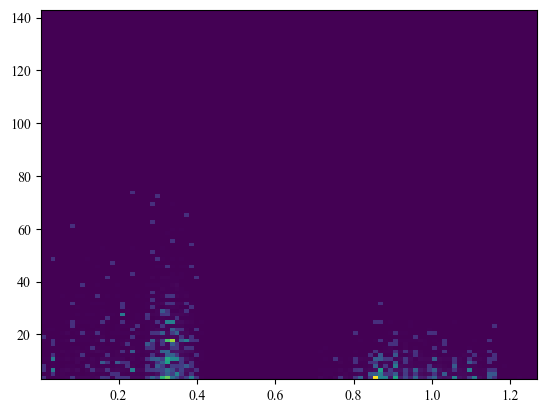

In [1052]:
plt.hist2d(all_ds, all_segl, bins = 100);

[Text(0.5, 1.0, 'Ensemble prediction'), Text(0.5, 1.0, 'Ensemble prediction')]

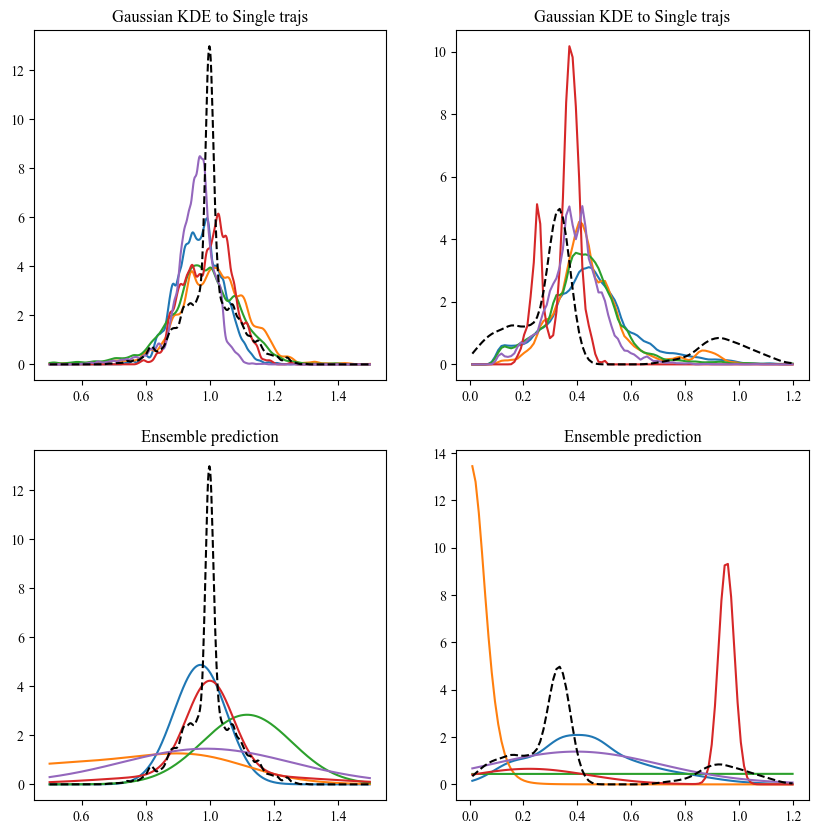

In [1062]:

colors = cmap(np.linspace(0, 1, num_teams))

fig, ax = plt.subplots(2,2, figsize = (2*5, 2*5))
alpha_values = np.linspace(0.5, 1.5, 500)
ds_values = np.linspace(0.01, 1.2, 100)

for idx, (preds_st, true_st, x_values) in enumerate(zip([pred_alphas, pred_ds], [true_alphas, true_ds], [alpha_values, ds_values])):
   
    for idxp, (pa, pe) in enumerate(zip(preds_st, pred_ens)):
    
        pa = pa[pa>0.1]        
        kde = gaussian_kde(pa)
        kde_values = kde(x_values)   
        ax[0, idx].plot(x_values, kde_values, label = ls)
    
        if idxp == 0: 
            kde = gaussian_kde(true_st)
            kde_values = kde(x_values)        
            
            ax[0, idx].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')
            ax[1, idx].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')
    
        if idx == 0:
            dist = multimode_dist(pe[:2,:].transpose(), pe[-1,:], (0,2), x_values)    
        else:
            dist = multimode_dist(pe[2:4,:].transpose(), pe[-1,:], (0,2), x_values)   
            
        ax[1, idx].plot(x_values, dist, label = le)
    
        
    
        ylim0 = ax[0, idx].get_ylim()
        ylim1 = ax[1, idx].get_ylim()
        
        # plt.setp(ax[:,idx], ylim = (min(ylim0[0],ylim1[0]), max(ylim0[1],ylim1[1])))


plt.setp(ax[0], title = 'Gaussian KDE to Single trajs')
plt.setp(ax[1], title = 'Ensemble prediction')

# plt.setp(ax, ylim = (0,5))

## Exp 8, 9

Text(0.5, 0, 'alpha')

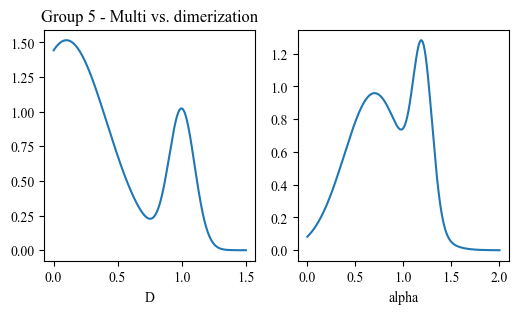

In [175]:
res1 = 0.75; res2 = 0.25
Pu_g5 = 0.05

res_time_dim = 1/Pu_g5
res_time_free = (res_time_dim)/res2*res1
P_dim = 1/res_time_free
M_g5 = np.array([[1-P_dim, P_dim], [Pu_g5, 1-Pu_g5]])

alphas_g5 = np.array([[0.7,	0.10],
                      [1.2,	0.01]])
Ds_g5 = np.array([[0.1,	0.1],
                  [1.0, 0.01]])

fig, ax = plt.subplots(1,2, figsize = (6,3))
ax[0].set_title('Group 5 - Multi vs. dimerization')
x = np.linspace(0.001,1.5,1000)
dist = multimode_dist(Ds_g5.tolist(), [res1, res2], bound = [1e-12,1e6], x = x)
ax[0].plot(x, dist)
ax[0].set_xlabel('D'); #ax[0].set_xscale('log')
x = np.linspace(0,2,1000)
dist = multimode_dist(alphas_g5.tolist(), [res1, res2], bound = [0,2], x = x)
ax[1].plot(x, dist)
ax[1].set_xlabel('alpha') 

### General ranking for exps

In [379]:
track = 2; task = 1;
exps = [8,9]

track_str = 'videos' if track == 1 else 'trajs'
task_str = 'single' if task == 1 else 'ens'
df_leaderboard = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv')
global_rank = df_leaderboard['Global rank'].values

ranks = []
metrics = []
for exp in exps:
    df_ranking = get_ranking_exp(track = track, task = task, exp = exp)
    ranks.append(df_ranking['Global Rank'].values)

    metrics.append(df_ranking.iloc[:, 1:6].values)

ranks = np.array(ranks)
metrics = np.array(metrics)

# Deleting far_naz from metrics
ranks = ranks[:,:-1]
metrics = metrics[:,:-1]
global_rank = global_rank[:-1]

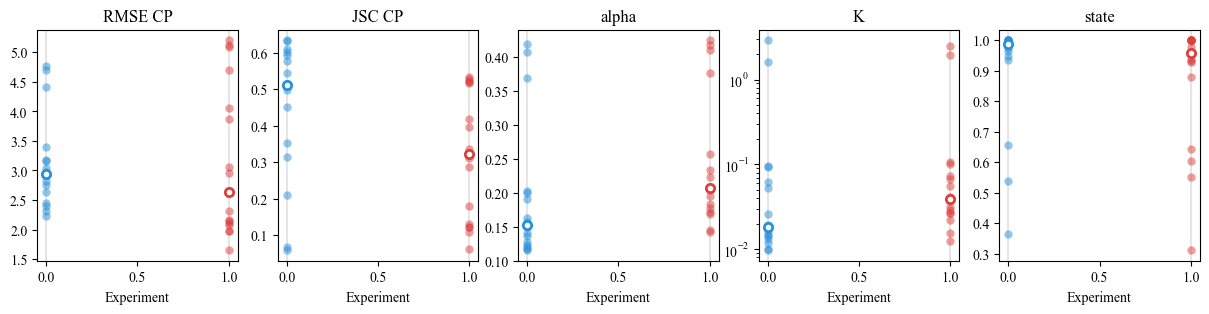

In [380]:
if task == 1:
    name_metrics = df_ranking.columns[1:6]
elif task == 2:
    name_metrics = df_ranking.columns[1:3]
fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

single_state = [10]

colors = cmap(np.linspace(0, 1, len(exps)))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)
    
    for exp, _ in enumerate(exps):
        axs[idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
        if exp in single_state and idxm == 0 and task == 1: 
            axs[idxm].axvline(exp, c =c_grey, ls = '--')
            continue

        metrics_plot = metrics[exp,:,idxm]

        if idxm == 0:
            metrics_plot = metrics_plot[metrics_plot != 0]
            
        axs[idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)

        axs[idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
    
plt.setp(axs[-2] if task == 1 else axs[-1], yscale = 'log')
plt.setp(axs, xlabel = 'Experiment');

### Segment length distribution

Text(0.5, 1.0, 'Distribution for length < 200')

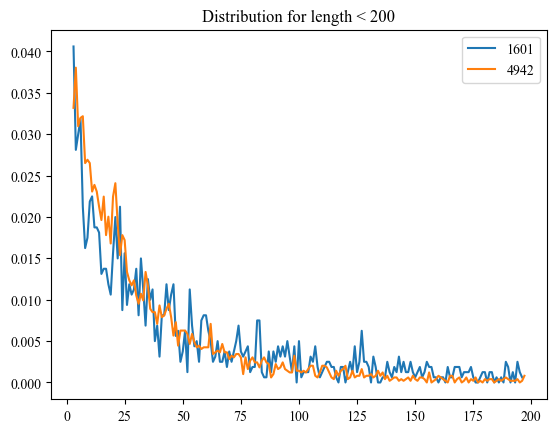

In [176]:
track = 2; task = 1
num_fovs = 30


for exp in exps:
    seg_1, seg_2 = [], []
    lengths = []
    seg_lengths = np.array([])
    for fov in range(num_fovs):
        df = load_file_to_df(path_ref(track, exp, fov))
        
        for cp, alphas, ds in zip(df.changepoints, df.alphas, df.Ds):
            cp = np.array([0]+cp)
            seg_l = cp[1:]-cp[:-1]

            # for s, a, d in zip(seg_l, alphas, ds):
            #     if get_state(a,d) == 0:
            #         seg_1.append(s)
            #     elif get_state(a,d) == 1:
            #         seg_2.append(s)
            if (seg_l < 200).any():   
                seg_lengths = np.append(seg_lengths, seg_l)
    
                seg_lengths = seg_lengths[seg_lengths < 200] 
            

            
            states = np.array(preds_fov.states.loc[idx])
        
    # bc1 = np.bincount(np.array(seg_1).astype(int))
    # bc2 = np.bincount(np.array(seg_2).astype(int))

    # plt.plot(np.arange(3, max(seg_1)+1), bc1[3:]/np.sum(bc1), c = c_main)
    # plt.plot(np.arange(3, max(seg_2)+1), bc2[3:]/np.sum(bc2), c = c_comp)

    # break
    bc = np.bincount(seg_lengths.astype(int))
    # print(bc[3]/np.sum(bc)*100, bc[-1]/np.sum(bc)*100)
    plt.plot(np.arange(3, max(seg_lengths)+1), bc[3:]/np.sum(bc), label = np.sum(bc))
plt.legend()
plt.title('Distribution for length < 200')

### Diffusion props

In [171]:
exps = [8,9]
num_teams = 5

TA = []
PA, PE = [], []
LS, LE = [], []

for exp in exps:
    print(exp)
    true_alphas = np.array([])
    
    pred_alphas = []
    pred_ens = []

    letters_s = []
    letters_e = []

    df_ranking = get_ranking_exp(track = track, task = 1, exp = exp).sort_values(by = 'Global Rank')
    df_ranking_ens = get_ranking_exp(track = track, task = 2, exp = exp).sort_values(by = 'Global Rank')

    LS.append(df_ranking.Team.values[:num_teams])
    LE.append(df_ranking_ens.Team.values[:num_teams])    
    
    for idxt, letter in enumerate(df_ranking.Team.values[:num_teams]):
        
        team_alphas = np.array([])
        team_pred_ens = []
        
        for fov in range(num_fovs):    

            ############# Single traj #############
            preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))             
            
            if idxt == 0:
                trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
              
            for idx in range(preds_fov.shape[0]):
    
                # Predicted pop
                cps = np.append(0, preds_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                alphas = np.array(preds_fov.alphas.loc[idx])
                states = np.array(preds_fov.states.loc[idx])
    
                
                seg_free = seg_l
                alpha_free = alphas
                for l, a in zip(seg_free, alpha_free):
                    team_alphas = np.append(team_alphas, np.ones(int(l))*a)
 
    
                # True pop
                if idxt == 0:
                    # Predicted pop
                    cps = np.append(0, trues_fov.changepoints.loc[idx])
                    seg_l = cps[1:]-cps[:-1]          
                    alphas = np.array(trues_fov.alphas.loc[idx])
                    states = np.array(trues_fov.states.loc[idx])
    
                    seg_free = seg_l#[states == 2]
                    alpha_free = alphas#[states == 2]
                    for l, a in zip(seg_free, alpha_free):
                        true_alphas = np.append(true_alphas, np.ones(int(l))*a)
        

        pred_alphas.append(team_alphas)
        
        # Ensemble
        letter_ens = df_ranking_ens.Team[idxt]
        path_pred_ens = f'data/challenge_phase/submissions_post15/{letter_ens}/track_{track}/exp_{exp}/ensemble_labels.txt'
        try:
            pred_ens.append(np.loadtxt(path_pred_ens, skiprows = 1, delimiter = ';'))
        except:
            print(letter_ens, dict_mapping[letter_ens])
    
                    
        

    TA.append(true_alphas)
    PA.append(pred_alphas)
    PE.append(pred_ens)
        

8
9


[Text(0.5, 1.0, 'Ensemble prediction')]

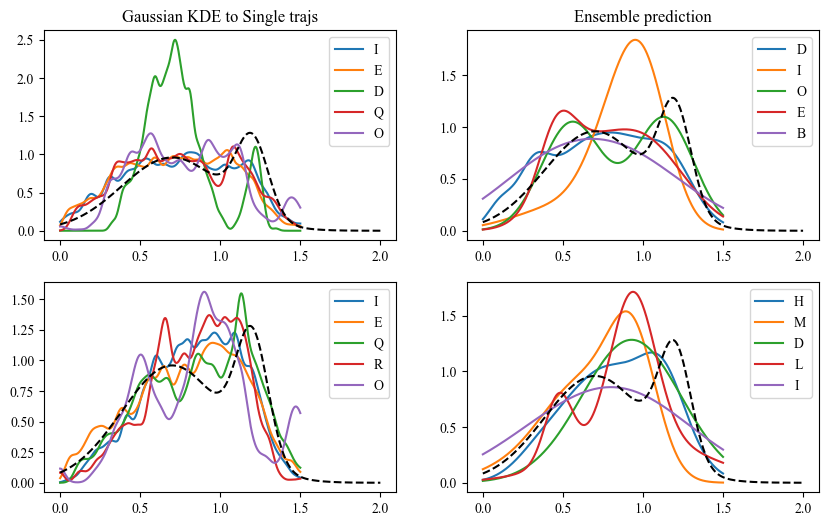

In [180]:

colors = cmap(np.linspace(0, 1, num_teams))

fig, ax = plt.subplots(2,2, figsize = (2*5, 2*3))
x_values = np.linspace(0, 1.5, 500)



for idxe, (pred_alphas, pred_ens, lss, les) in enumerate(zip(PA, PE, LS, LE)):
    
    
    for idxp, (pa, pe, ls, le) in enumerate(zip(pred_alphas, pred_ens, lss, les)):

        # paf = paf[paf>0.1]        
        kde = gaussian_kde(pa)
        kde_values = kde(x_values)        
        
        ax[idxe,0].plot(x_values, kde_values, label = ls)

        if idxp == 0:
            pa = TA[idxe]
            
            # Gotten from trajectories       
            kde = gaussian_kde(pa)
            kde_values = kde(x_values)        
            
            # ax[idxe,0].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')
            # ax[idxe,1].plot(x_values, kde_values, c = 'k', zorder = 50, ls = '--')

            # From values
            # x_D = np.linspace(0.001,1.5,1000)
            # dist_D = multimode_dist(Ds_g5.tolist(), [res1, res2], bound = [1e-12,1e6], x = x_D)
            # ax[0].plot(x_D, dist_D)
            
            x_alpha = np.linspace(0,2,1000)
            dist_alpha = multimode_dist(alphas_g5.tolist(), [res1, res2], bound = [0,2], x = x_alpha)
            ax[idxe, 0].plot(x_alpha, dist_alpha, c = 'k', zorder = 50, ls = '--')
            ax[idxe, 1].plot(x_alpha, dist_alpha, c = 'k', zorder = 50, ls = '--')  
            

        
        dist = multimode_dist(pe[:2,:].transpose(), pe[-1,:], (0,2), x_values)    
        ax[idxe,1].plot(x_values, dist, label = le)

        ax[idxe,0].legend()
        ax[idxe,1].legend()

        ylim0 = ax[idxe,0].get_ylim()
        ylim1 = ax[idxe,1].get_ylim()
        
        # plt.setp(ax[idxe], ylim = (min(ylim0[0],ylim1[0]), max(ylim0[1],ylim1[1])))


            

        # if idxe != 0:
        #     pap = pap[pap<2]        
        #     kde = gaussian_kde(pap)
        #     x_values = np.linspace(min(pap), max(pap), 100)
        #     kde_values = kde(x_values)  
    
        #     ax[idxe].plot(x_values, kde_values, c = colors_r[idxp])
        
plt.setp(ax[0,0], title = 'Gaussian KDE to Single trajs')
plt.setp(ax[0,1], title = 'Ensemble prediction')

# plt.setp(ax, ylim = (0,5))

#### Metrics for segments < 200

In [126]:
exps = [8, 9]


df_ranking = pd.read_csv(path_leaderboard('trajs', 'single'))
letters = get_letter_from_teams(df_ranking.Team.values)

dfs_exp = []

for exp in exps:   
    print(exp)

    dfs_cutoff = []
    
    for idxc, cutoff_length in enumerate([199, 210]):

        df_exp_cl = pd.DataFrame(columns=['Team',	'RMSE CP',	'JSC CP',	'alpha',	'K',	'state'])
    
        try: 
            del df_true_exp
        except: 
            pass
    
        
        
        for idxt, letter in enumerate(letters):
            
            try:
                del df_pred_exp
            except:
                pass           
            
            for fov in range(num_fovs):
    
                if idxt == 0:
                    trues_fov = load_file_to_df(path_ref(track, exp, fov))     
                    traj_idx_values = trues_fov.loc[~trues_fov['changepoints'].apply(
                        lambda cps: (np.append(0, cps)[1:] - np.append(0, cps)[:-1] >= cutoff_length).any()), 'traj_idx'].values.astype(int)            
                
                    
                    filtered_trues_fov = trues_fov[trues_fov['traj_idx'].isin(traj_idx_values)]
                    filtered_trues_fov['traj_idx'] = np.arange(filtered_trues_fov.shape[0])
    
                    # Full experiment dataframe
                    try:
                        filtered_trues_fov.traj_idx += df_true_exp.traj_idx.values[-1]+1
                        df_true_exp = pd.concat([df_true_exp, filtered_trues_fov]) 
                    except:            
                        df_true_exp = filtered_trues_fov
                        
                
                preds_fov = load_file_to_df(path_pred(letter,track,exp,fov)) 
                
                filtered_preds_fov = preds_fov[preds_fov['traj_idx'].isin(traj_idx_values)]
                filtered_preds_fov['traj_idx'] = np.arange(filtered_preds_fov.shape[0])
    
                try:                
                    filtered_preds_fov.traj_idx += df_pred_exp.traj_idx.values[-1]+1
                    df_pred_exp = pd.concat([df_pred_exp, filtered_preds_fov])
                except:            
                    df_pred_exp = filtered_preds_fov
    
            rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp = error_SingleTraj_dataset(df_pred_exp, 
                                                                                                  df_true_exp, 
                                                                                                  prints = False, disable_tqdm=True);

            
            df_exp_cl.loc[df_exp_cl.shape[0], :] = [letter, rmse_CP_exp, JI, error_alpha_exp, error_D_exp, error_s_exp]
            
            
            
        dfs_cutoff.append(df_exp_cl)
        if idxc == 0:
            df_exp_cl.to_csv(f'figures/dimerization_advantage/df_letter_{letter}_exp_{exp}_with_cutoff.csv')
            
    dfs_exp.append(dfs_cutoff)
    
        

8
9


Cutoff: 0 RMSE CP 0 0 6
Cutoff: 0 RMSE CP 0 1 6
Cutoff: 0 JSC CP 1 0 0
Cutoff: 0 JSC CP 1 1 0
Cutoff: 0 alpha 2 0 0
Cutoff: 0 alpha 2 1 0
Cutoff: 0 K 3 0 0
Cutoff: 0 K 3 1 0
Cutoff: 0 state 4 0 0
Cutoff: 0 state 4 1 0
Cutoff: 1 RMSE CP 0 0 2
Cutoff: 1 RMSE CP 0 1 4
Cutoff: 1 JSC CP 1 0 0
Cutoff: 1 JSC CP 1 1 0
Cutoff: 1 alpha 2 0 0
Cutoff: 1 alpha 2 1 0
Cutoff: 1 K 3 0 16
Cutoff: 1 K 3 1 0
Cutoff: 1 state 4 0 0
Cutoff: 1 state 4 1 0


Text(0.1, 0.25, 'All trajs.')

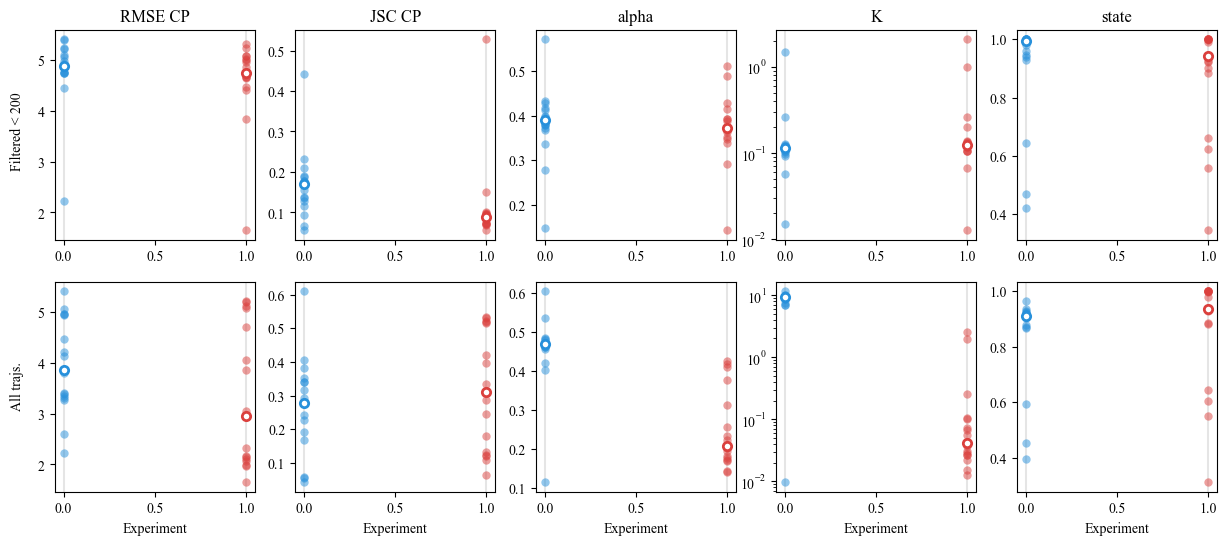

In [398]:
if task == 1:
    name_metrics = df_ranking.columns[1:6]
elif task == 2:
    name_metrics = df_ranking.columns[1:3]
fig, axs = plt.subplots(2, len(name_metrics), figsize = (len(name_metrics)*3, 2*3))
colors = cmap(np.linspace(0, 1, len(exps)))

for idxc, cutoff in enumerate([198,201]):

    for idxm, name in enumerate(name_metrics):
        if idxc == 0:
            axs[0, idxm].set_title(name)
        
        for exp, _ in enumerate(exps):
            axs[idxc, idxm].axvline(exp, c='k', alpha = 0.1, zorder = -1)
    
            metrics_plot = dfs_exp[exp][idxc].iloc[:, 1:].values[:, idxm]  

            print('Cutoff:', idxc, name, idxm, exp, np.sum(metrics_plot > 5))
    
            # if idxm == 0:
            #     metrics_plot = metrics_plot[metrics_plot != 0]
                
            axs[idxc, idxm].scatter(np.ones(metrics_plot.shape[0])*exp, metrics_plot, alpha = 0.5, color = colors[exp], lw = 0)
    
            axs[idxc, idxm].scatter(exp, np.median(metrics_plot), edgecolor = colors[exp], facecolor = 'w', lw = 2)
        
plt.setp(axs[:, -2], yscale = 'log')
plt.setp(axs[1,:], xlabel = 'Experiment');
fig.text(0.1, 0.65, 'Filtered < 200', ha='center', rotation = 90)
fig.text(0.1, 0.25, 'All trajs.', ha='center', rotation = 90)

In [418]:
exp = 0; idxc = 0
dfs_exp[exp][idxc].sort_values(by = 'Team', ascending = True)

,Team,RMSE CP,JSC CP,alpha,K,state
14,A,4.973615,0.11554,0.571176,0.101625,0.469697
7,B,5.107133,0.067368,0.412622,0.114264,1.0
10,C,4.856068,0.156098,0.371291,0.109857,0.996245
2,D,5.053765,0.135177,0.337045,0.091177,1.0
1,E,5.246314,0.178495,0.395869,0.111342,1.0
9,F,4.92489,0.169775,0.427555,0.098003,0.981572
12,G,4.886429,0.172324,0.41643,0.125017,0.944578
11,H,5.411628,0.127682,0.378137,1.496021,1.0
0,I,2.234429,0.441406,0.14798,0.014908,0.960126
5,K,4.738897,0.139026,0.390812,0.124887,1.0


In [457]:
df_leaderboard[:-1].keys()

Index(['Global rank', 'Team', 'RMSE (CP) ', 'JSC (CP) ', 'MAE (alpha) ',
       'MSLE (K) ', 'F1 (diff. type) ', 'RMSE rank', 'JI rank', 'MAE rank',
       'MSLE rank', 'F1 rank', 'MRR'],
      dtype='object')

In [463]:
dim

array([0.44140625, 0.17849462365591398, 0.13517665130568357,
       0.18782479584261322, 0.18986438258386867, 0.13902611150317573,
       0.17709019091507572, 0.06736842105263158, 0.20932009167303284,
       0.16977491961414792, 0.15609756097560976, 0.12768184196755625,
       0.17232375979112272, 0.23272438443208895, 0.11554015020219527,
       0.09468984962406016, 0.056989771066731615], dtype=object)

In [464]:
multi

array([0.5278564683663833, 0.09342128721697272, 0.07444794952681388,
       0.09551689528270324, 0.10072859744990892, 0.056210335448776065,
       0.08980073413738857, 0.08611013679410733, 0.09832472209174886,
       0.07246068848278793, 0.09512683578104139, 0.07269116186693148,
       0.07325417589052123, 0.09319811155796467, 0.06782178217821783,
       0.15131042516016308, 0.08441842174255003], dtype=object)

In [127]:
idxc = 0

In [128]:
dim = dfs_exp[0][idxc]['JSC CP'].values
multi = dfs_exp[1][idxc]['JSC CP'].values
team = dfs_exp[0][idxc]['Team'].values

# avg_jsc = np.mean([dim, multi], axis = 0)

avg_jsc = df_leaderboard[:-1]['JSC (CP) '].values

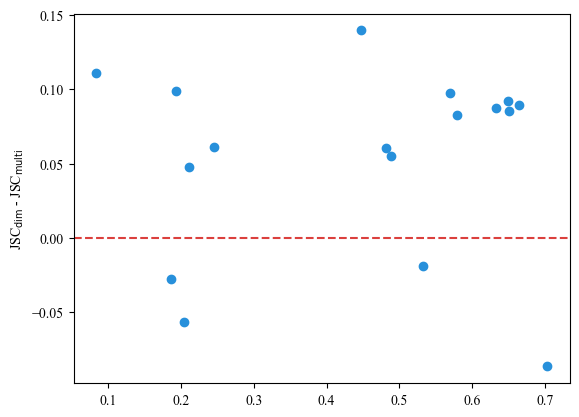

In [469]:
fig, ax = plt.subplots()
ax.plot(avg_jsc, dim - multi, 'o', c = c_main)
ax.axhline(0, c = c_comp, ls = '--')

plt.setp(ax,# xticks = np.arange(len(team)), xticklabels = team,
         ylabel = r'JSC$_\mathrm{dim}$ - JSC$_\mathrm{multi}$'        
        );

In [471]:
dfs_exp[0][idxc].columns[1:]

Index(['RMSE CP', 'JSC CP', 'alpha', 'K', 'state'], dtype='object')

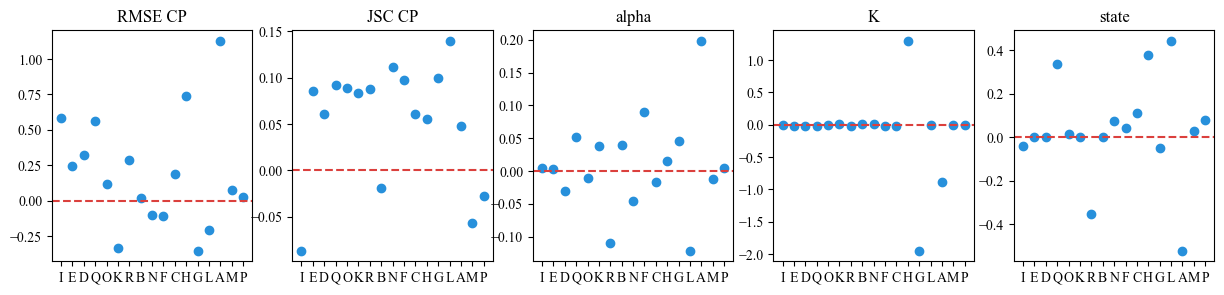

In [474]:
idxc = 0

name_metrics = dfs_exp[0][idxc].columns[1:]
team = dfs_exp[0][idxc]['Team'].values

fig, axs = plt.subplots(1, len(name_metrics), figsize = (len(name_metrics)*3, 3))

for idxm, name in enumerate(name_metrics):
    axs[idxm].set_title(name)

    dim = dfs_exp[0][idxc][name].values
    multi = dfs_exp[1][idxc][name].values

    axs[idxm].plot(team, dim - multi, 'o', c = c_main)
    axs[idxm].axhline(0, c = c_comp, ls = '--')

## Exp 11

In [45]:
exp = 11; track = 2; task = 1

In [52]:
tpops = []
ppops = []

num_teams = 5

df_ranking = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_single.csv')
letters = get_letter_from_teams(df_ranking.Team.values)


true_state_pops = np.zeros(len(models_phenom().lab_state))

true_trap_dist = np.array([])
true_free_dist = np.array([])

pred_state_pops, pred_trap_dist, pred_free_dist = [], [], []
print(exp)

for idxt, letter in enumerate(letters[:num_teams]):
    
    state_pops = np.zeros(len(models_phenom().lab_state))
    free_dist = np.array([])
    trap_dist = np.array([])
    for fov in range(num_fovs):    
        
        preds_fov = load_file_to_df(path_pred(letter,track,exp,fov))   
        
        if idxt == 0:
            trues_fov = load_file_to_df(path_ref(track, exp, fov)) 
        
        
        for idx in range(preds_fov.shape[0]):

            # Predicted pop
            cps = np.append(0, preds_fov.changepoints.loc[idx])
            seg_l = cps[1:]-cps[:-1]            
            states = preds_fov.states.loc[idx] 
            
            for l, s in zip(seg_l, states):
                state_pops[int(s)] += l

                if s == 0:
                    trap_dist = np.append(trap_dist, l)
                elif s == 2:
                    free_dist = np.append(free_dist, l)
                    

            # True pop
            if idxt == 0:
                # Predicted pop
                cps = np.append(0, trues_fov.changepoints.loc[idx])
                seg_l = cps[1:]-cps[:-1]            
                states = trues_fov.states.loc[idx] 
                
                for l, s in zip(seg_l, states):
                    true_state_pops[int(s)] += l

                    if s == 0:
                        true_trap_dist = np.append(true_trap_dist, l)
                    else:
                        true_free_dist = np.append(true_free_dist, l)
                        

    pred_state_pops.append(state_pops)
    pred_trap_dist.append(trap_dist)
    pred_free_dist.append(free_dist) 
#     plt.bar(np.arange(4)+idxt*0.1-0.2, state_pops, width = 0.1)
# plt.bar(np.arange(4), true_state_pops, width = 0.5, facecolor = 'k', alpha = 0.3)
        

11


18.749699157641395 10.681252776543758


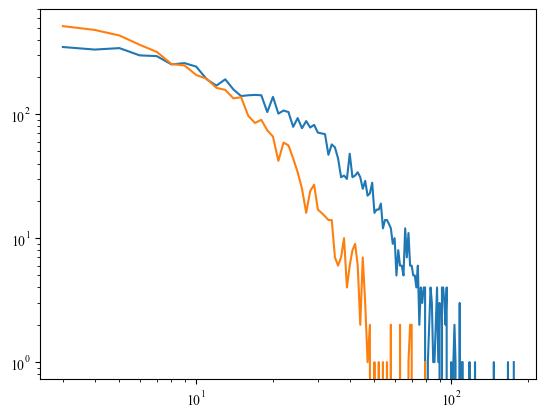

In [1503]:
free = np.bincount(true_free_dist.astype(int))
trap = np.bincount(true_trap_dist.astype(int))

plt.loglog(np.arange(3, len(free)), free[3:])
plt.plot(np.arange(3, len(trap)), trap[3:])

print(np.mean(true_free_dist), np.mean(true_trap_dist))

[-0.3,
 1.3,
 Text(0, 0.5, 'Residence time'),
 Text(0, 0, 'Trapped'),
 Text(1, 0, 'Free / Directed')]

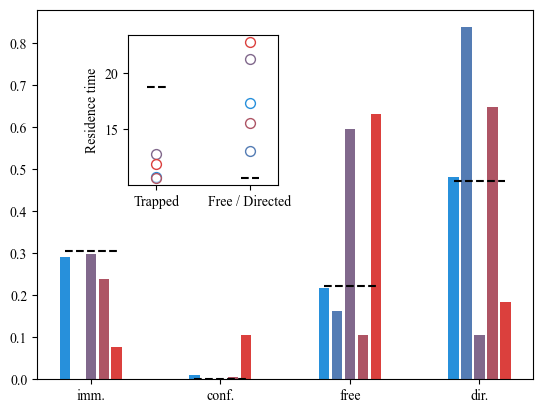

In [54]:
fig, axs = plt.subplots()

colors = cmap(np.linspace(0, 1, num_teams))

         
for idxt, state_pops in enumerate(pred_state_pops):        
    axs.bar(np.arange(4)+idxt*0.1-(0.1*np.floor(num_teams/2)), state_pops/state_pops.sum(), width = 0.08, facecolor = colors[idxt])
    

for idxtp, tp in enumerate(true_state_pops/true_state_pops.sum()):
    axs.plot([idxtp-(0.1*np.floor(num_teams/2)), idxtp+(0.1*np.floor(num_teams/2))],
                   [tp, tp],
                   ls = '--', c = 'k')
# axs[idxe].bar(np.arange(4), tpops[idxe]/tpops[idxe].sum(), width = 0.8, facecolor = 'k', alpha = 0.3, zorder = -5)
plt.setp(axs, xticks = np.arange(4), xticklabels = ['imm.', 'conf.', 'free', 'dir.']);



axs_in = inset_axes(axs, width=1.5, height=1.5, bbox_to_anchor=(0.5, 0.95, 0, 0), bbox_transform=axs.transAxes) 

width = 0.1

axs_in.plot([-width, width], [np.mean(true_free_dist), np.mean(true_free_dist)], c = 'k', ls = '--')
axs_in.plot([1-width, 1+width], [np.mean(true_trap_dist), np.mean(true_trap_dist)], c = 'k', ls = '--')

for free_dist, trap_dist, c in zip(pred_free_dist, pred_trap_dist, colors):
    axs_in.scatter([0,1], [np.mean(trap_dist), np.mean(free_dist)], facecolor = (1,1,1,0.5), edgecolor = c, s = 50)

plt.setp(axs_in, xlim = [-0.3, 1.3], ylabel = 'Residence time',
        xticks = [0,1], xticklabels = ['Trapped', 'Free / Directed'])


## Ensemble task

### Number of states

In [1649]:
path_leaderboard??

Signature: path_leaderboard(track, task)
Docstring: <no docstring>
Source:    path_leaderboard = lambda track, task: path_folders+f'final_leaderboards/Final_leaderboard_{track_str}_{task_str}.csv'
File:      /tmp/ipykernel_130672/2936843653.py
Type:      function


In [167]:
track = 2
df = pd.read_csv(path_leaderboard('trajs', 'ens'))
letters = get_letter_from_teams(df.Team.values)

In [197]:
method_ens_list = [None,None,None,None,'GMM','GMM',None,'cluster','GMM',None,'cluster','cluster',None,'cluster','GMM',None,None,None]
all_letters = 'ABCDEFGHIJKLMNOPQR'
methods_ens = {l : v for l, v in zip(all_letters, method_ens_list)}

track = 2

df = pd.read_csv(path_leaderboard('trajs','ens'))
df['method'] = [methods_ens[l] for l in get_letter_from_teams(df.Team.values)]
colors_method = np.array(['C1']*df.shape[0], dtype = object)
colors_method[df.method.values == None] = 'grey'
colors_method[df.method.values == 'cluster'] = 'C2'

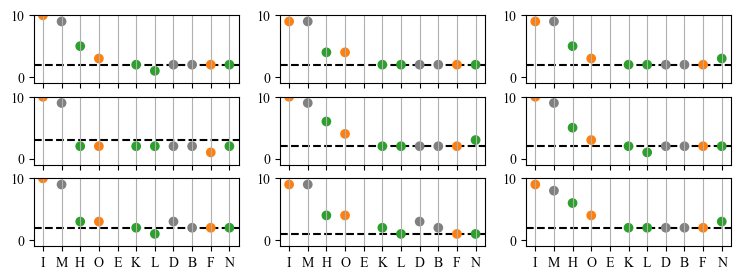

In [220]:
exps = np.arange(12)
# Deleting faulty multistate + confinment big
exps = correct_exps

true_props = {'ls' : '--', 'c' : 'k', 'zorder' : -20}

fig, axs = plt.subplots(3, 3, figsize = (3*3, 3*1))
for idxe, (exp, ax) in enumerate(zip(exps, axs.flatten())):
    
    true = np.loadtxt(path_ref_ens(track, exp), skiprows = 1, delimiter = ';')

    num_states = []
    for idxl, letter in enumerate(letters):                  
        
        pred = np.loadtxt(path_pred_ens(letter, track, exp), skiprows = 1, delimiter = ';')

        if len(pred.shape) == 1:
            pops = pred[-1]
            num_states.append(1)
        else:
            pops = pred[-1,:]
            num_states.append(pred.shape[1])

    ax.scatter(np.arange(len(num_states)), num_states,  color = colors_method)

    if len(true.shape) == 1:
            ax.axhline(1, **true_props)
    else:
            ax.axhline(true.shape[1], **true_props)

    
plt.setp(axs[:-1,:], xticks = np.arange(len(letters)), xticklabels = []);   
plt.setp(axs[-1,:],  xticks = np.arange(len(letters)), xticklabels = letters);
plt.setp(axs, ylim = (-1, 10))

for ax in axs.flatten(): ax.xaxis.grid(True)

### Model prediction

In [161]:
df = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')
teams = df['Team'].values
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')
dict_inv = dict((v,k) for k,v in dict_mapping.items())
letters = [dict_inv[key] for key in teams]

In [165]:
data = []

for exp in range(11):
    row = {}
    
    # Extract the true model
    true_file = path_ref_ens(track, exp)
    with open(true_file, 'r') as f:
        true_model = f.readline().split(';')[0].split(': ')[1].strip()
    row['True Model'] = true_model

    # Extract predictions for each letter
    for letter in letters:
        pred_file = path_pred_ens(letter, track, exp)
        with open(pred_file, 'r') as f:
            pred_model = f.readline().split(';')[0].split(': ')[1].strip()
        row[letter] = pred_model

    data.append(row)

# Create DataFrame
df = pd.DataFrame(data)


In [167]:
df

,True Model,I,M,H,O,E,K,L,D,B,F,N
0,confinement,single_state,dimerization,immobile_traps,multi-state,multi_state,multi_state,dimerization,single_state,multi_state,confinement,multi_state
1,multi_state,single_state,single_state,dimerization,multi-state,multi_state,multi_state,dimerization,single_state,multi_state,confinement,multi_state
2,immobile_traps,immobile_traps,confinement,immobile_traps,multi-state,multi_state,multi_state,single_state,immobile_traps,multi_state,confinement,multi_state
3,confinement,confinement,single_state,multi_state,multi-state,multi_state,multi_state,dimerization,immobile_traps,multi_state,confinement,multi_state
4,dimerization,multi_state,confinement,multi_state,multi-state,multi_state,multi_state,dimerization,dimerization,multi_state,confinement,multi_state
5,multi_state,multi_state,dimerization,single_state,multi-state,multi_state,multi_state,single_state,confinement,multi_state,confinement,multi_state
6,multi_state,multi_state,immobile_traps,multi_state,multi-state,multi_state,multi_state,c,confinement,multi_state,confinement,multi_state
7,dimerization,multi_state,multi_state,multi_state,multi-state,multi_state,multi_state,dimerization,dimerization,multi_state,confinement,multi_state
8,dimerization,dimerization,dimerization,immobile_traps,multi-state,multi_state,multi_state,single_state,dimerization,multi_state,confinement,multi_state
9,multi_state,multi_state,immobile_traps,single_state,multi-state,multi_state,multi_state,single_state,multi_state,multi_state,confinement,multi_state


### Ranking plots

In [161]:
df = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')
teams = df['Team'].values
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')
dict_inv = dict((v,k) for k,v in dict_mapping.items())
letters = [dict_inv[key] for key in teams]

In [163]:
letters

['I', 'M', 'H', 'O', 'E', 'K', 'L', 'D', 'B', 'F', 'N']

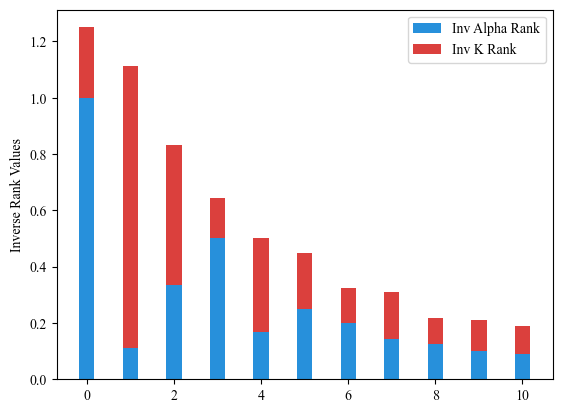

In [162]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract columns as numpy arrays and compute the inverses
inv_alpha_rank = 1 / df['alpha rank'].to_numpy()
inv_k_rank = 1 / df['K rank'].to_numpy()

# Plotting
indices = np.arange(len(inv_alpha_rank))
width = 0.35

fig, ax = plt.subplots()
ax.bar(indices, inv_alpha_rank, width, label='Inv Alpha Rank', facecolor = c_main)
ax.bar(indices, inv_k_rank, width, bottom=inv_alpha_rank, label='Inv K Rank', facecolor = c_comp)

ax.set_ylabel('Inverse Rank Values')
ax.legend()

plt.show()


### Histograms predictions


#### Group 1: comparing confinemnet to multistate


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


0.28865624048467137
0.15507115703253851


[None, None]

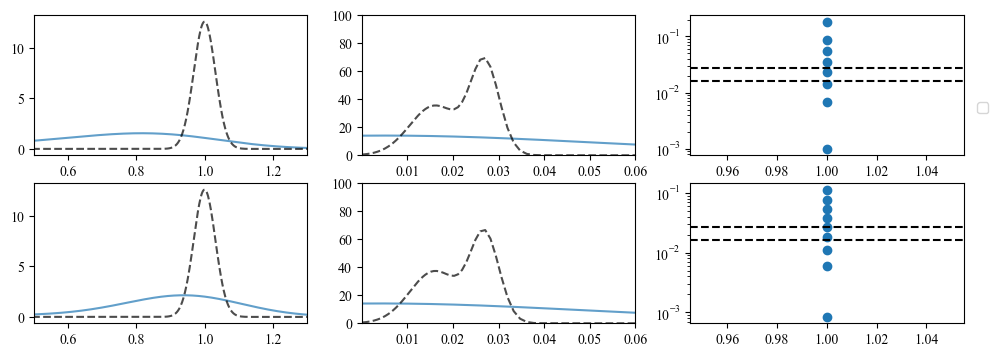

In [1174]:
fig, ax = plt.subplots(2, 3, figsize = (12,4))

for idxe, exp in enumerate(groups[0]):
    # if idxe == 1:break
    for idxl, letter in enumerate(letters[:5]):

        if letter  != 'M':
            continue

        
            
        path_pred = f'data/challenge_phase/submissions_post15/{letter}/track_{track}/exp_{exp}/ensemble_labels.txt'
        path_true = f'data/challenge_phase/reference_challenge_phase/track_{track}/exp_{exp}/ensemble_labels.txt'
        
        true = np.loadtxt(path_true, skiprows = 1, delimiter = ';')
        # true[1,:] = true[1,:]**2
        # 3,:] = true[3,:]**2true[
        pred = np.loadtxt(path_pred, skiprows = 1, delimiter = ';')
     
    
        if letter == 'H': 
            pred = pred[:,:1]
        dist_a, dist_D,dists = error_Ensemble_dataset(true, pred, return_distributions=True, size_support = 1000)
        print(dist_a)
        true_a, true_D, pred_a, pred_D = dists
        
       
        
        x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                              models_phenom().bound_alpha[1], true_a.shape[0])    
        ax[idxe, 0].plot(x_alpha, pred_a, alpha = 0.7)

        
        x_D = np.logspace(np.log10(models_phenom().bound_D[0]), 
                          np.log10(models_phenom().bound_D[1]), true_D.shape[0]) 
        ax[idxe, 1].plot(x_D, pred_D, alpha = 0.7, label = letter)

        ax[idxe, 2].scatter(np.ones_like(pred[2,:])*idxl, pred[2,:])

        
    ax[idxe,0].plot(x_alpha, true_a, alpha = 0.7, c = 'k', ls = '--', )
    ax[idxe,1].plot(x_D, true_D, alpha = 0.7, c = 'k', ls = '--', )
    for mean in true[2,:]:
        ax[idxe,2].axhline(mean,  c = 'k', ls = '--')
    
ax[0,2].legend(loc = (1.05, 0.3))
plt.setp(ax[:,0], xlim = (0.5,1.3));
plt.setp(ax[:,1], xlim = (4e-6, 0.06), ylim = (0,100));
plt.setp(ax[:,2], yscale = 'log')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[None, None]

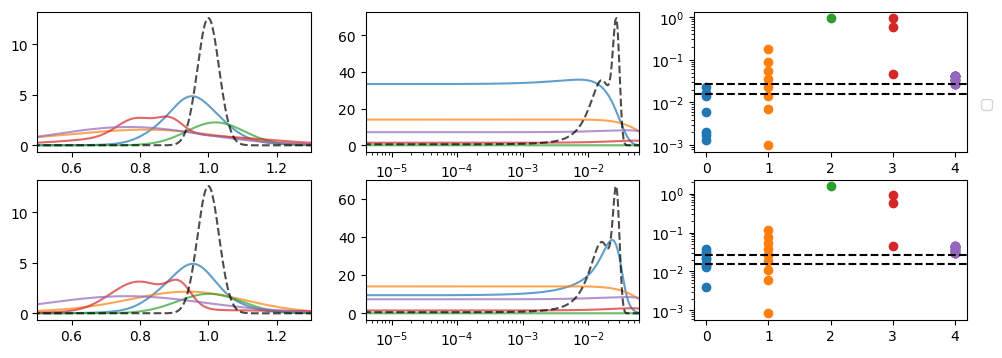

In [704]:
fig, ax = plt.subplots(2, 3, figsize = (12,4))

for idxe, exp in enumerate(groups[0]):

    for idxl, letter in enumerate(letters[:5]):

        
            
        path_pred = f'data/challenge_phase/submissions_post15/{letter}/track_{track}/exp_{exp}/ensemble_labels.txt'
        path_true = f'data/challenge_phase/reference_challenge_phase/track_{track}/exp_{exp}/ensemble_labels.txt'
        
        true = np.loadtxt(path_true, skiprows = 1, delimiter = ';')
        pred = np.loadtxt(path_pred, skiprows = 1, delimiter = ';')


        if letter == 'H': 
            pred = pred[:,:1]
        _,dist_D,dists = error_Ensemble_dataset(true, pred, return_distributions=True, size_support = 1000)
        true_a, true_D, pred_a, pred_D = dists
        
       
        
        x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                              models_phenom().bound_alpha[1], true_a.shape[0])    
        ax[idxe, 0].plot(x_alpha, pred_a, alpha = 0.7)

        
        x_D = np.logspace(np.log10(models_phenom().bound_D[0]), 
                          np.log10(models_phenom().bound_D[1]), true_D.shape[0]) 
        ax[idxe, 1].plot(x_D, pred_D, alpha = 0.7, label = letter)

        ax[idxe, 2].scatter(np.ones_like(pred[2,:])*idxl, pred[2,:])

        
    ax[idxe,0].plot(x_alpha, true_a, alpha = 0.7, c = 'k', ls = '--', )
    ax[idxe,1].plot(x_D, true_D, alpha = 0.7, c = 'k', ls = '--', )
    for mean in true[2,:]:
        ax[idxe,2].axhline(mean,  c = 'k', ls = '--')
    
ax[0,2].legend(loc = (1.05, 0.3))
plt.setp(ax[:,0], xlim = (0.5,1.3));
plt.setp(ax[:,1], xlim = (4e-6, 0.06), xscale = 'log');
plt.setp(ax[:,2], yscale = 'log')

#### Group 5: comparing dimerization to multistate


In [1697]:
groups

[[0, 1, 2], [3], [4], [5, 6], [7], [8]]

In [1694]:
track = 2; task = 2;
track_str = 'videos' if track == 1 else 'trajs'
task_str = 'single' if task == 1 else 'ens'
df_leaderboard = pd.read_csv(path_leaderboard(track_str, task_str))

letters = get_letter_from_teams(df_leaderboard.Team.values)

In [1705]:
letters[:5]

['I', 'M', 'H', 'O', 'E']

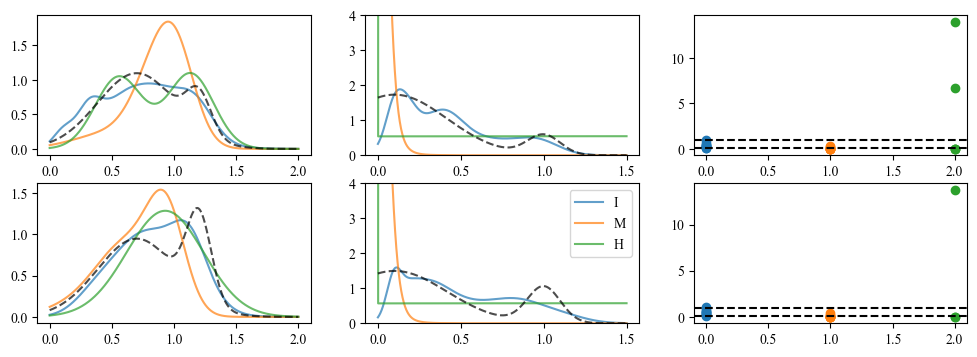

In [1730]:
fig, ax = plt.subplots(2, 3, figsize = (12,4))

size_support = 1000
x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                              models_phenom().bound_alpha[1], size_support)
    
x_D = np.linspace(0, 1.5, size_support) 

for idxe, exp in enumerate([8,9]):

    true = np.loadtxt(path_ref_ens(track, exp), skiprows = 1, delimiter = ';')

    true_a = multimode_dist(true[:2,:].transpose(), weights = true[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
    true_D = multimode_dist(true[2:4,:].transpose(), weights = true[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)


    for idxl, letter in enumerate(letters[:3]):

        pred = np.loadtxt(path_pred_ens(letter, track, exp), skiprows = 1, delimiter = ';')
        # pred[1,:] = pred[1,:]**2
        # pred[3,:] = pred[3,:]**2
        
        # True
        
        
        pred_a = multimode_dist(pred[:2,:].transpose(), weights = pred[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
        pred_D = multimode_dist(pred[2:4,:].transpose(), weights = pred[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)
        
    
        ax[idxe, 0].plot(x_alpha, pred_a, alpha = 0.7)
        ax[idxe, 1].plot(x_D, pred_D, alpha = 0.7, label = letter)

        ax[idxe, 2].scatter(np.ones_like(pred[2,:])*idxl, pred[2,:])

        
    ax[idxe,0].plot(x_alpha, true_a, alpha = 0.7, c = 'k', ls = '--', )
    ax[idxe,1].plot(x_D, true_D, alpha = 0.7, c = 'k', ls = '--')
    for mean in true[2,:]:
        ax[idxe,2].axhline(mean,  c = 'k', ls = '--')

ax[idxe, 1].legend()
# ax[0,2].legend(loc = (1.05, 0.3))
#plt.setp(ax[:,0], xlim = (0.5,1.3));
plt.setp(ax[:,1], ylim = (0, 4));
# plt.setp(ax[:,2], yscale = 'log')

In [1725]:
df_leaderboard

,Global rank,Team,W1 (alpha):,W1 (K):,alpha rank,K rank,MRR
0,1,UCL SAM,0.138,0.058,1,4,0.250
1,2,DeepSPT,0.267,0.050,9,1,0.222
2,3,Nanoninjas,0.192,0.051,3,2,0.167
3,4,bjyong,0.188,0.084,2,7,0.129
4,5,SPT-HIT,0.231,0.057,6,3,0.100
5,6,ICSO UPV,0.218,0.067,4,5,0.090
6,7,HSC AI,0.230,0.256,5,8,0.065
7,8,Unfriendly AI,0.238,0.072,7,6,0.062
8,9,EmetBrown,0.259,0.622,8,11,0.043
9,10,BIOMED-UCA,0.275,0.534,10,9,0.042


### 2D histograms

In [1150]:
def get_histograms_data(path, x_a = None, x_d = None, return_probs = False):

    if x_a is None:
        x_a = np.linspace(0,2,1000)
    if x_d is None:
        x_d = np.linspace(0,2,1000)

    vals = np.loadtxt(path, skiprows = 1, delimiter = ';')

    Z = np.zeros((x_a.shape[0], x_d.shape[0]))
    
    for idx_state in range(vals.shape[1]):
    
        prob_a_state = multimode_dist(vals[:2, idx_state].transpose(), weights = vals[-1, idx_state], bound = [x_a.min(), x_a.max()], x = x_a)    
        
        prob_d_state = multimode_dist(vals[2:4, idx_state].transpose(), weights = vals[-1, idx_state], bound = [x_d.min(), x_d.max()], x = x_d)

        Z += np.outer(prob_a_state, prob_d)

    if return_probs:
        return Z, prob_a, prob_d
    else:
        return Z

In [1148]:
path = path_ref_ens(2,6)

x_d = np.linspace(0,1.25,10)
x_a = np.linspace(0,1.5,10)

vals = np.loadtxt(path, skiprows = 1, delimiter = ';')

Z = np.zeros((x_a.shape[0], x_d.shape[0]))

for idx_state in range(vals.shape[1]):

    prob_a_state = multimode_dist(vals[:2, idx_state].transpose(), weights = vals[-1, idx_state], bound = [x_a.min(), x_a.max()], x = x_a)    
    
    prob_a_state = multimode_dist(vals[2:4, idx_state].transpose(), weights = vals[-1, idx_state], bound = [x_d.min(), x_d.max()], x = x_d)

    Z += np.outer(prob_a_state, prob_a_state)

In [1166]:
df_leaderboard.keys()

Index(['Global rank', 'Team', 'W1 (alpha): ', 'W1 (K): ', 'alpha rank',
       'K rank', 'MRR'],
      dtype='object')

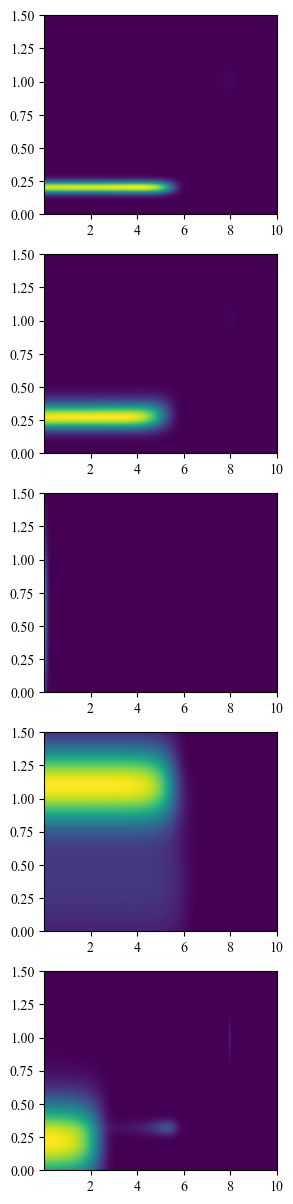

In [1161]:
exp = 3
x_d = np.logspace(-4,1,1000)
x_a = np.linspace(0,1.5,1000)


fig, ax = plt.subplots(5, 1, figsize=(3, 5*3))

# True distribution
Z = get_histograms_data(path_ref_ens(2, exp), x_a = x_a, x_d = x_d)
ax[0].imshow(Z, extent=[x_d.min(), x_d.max(), x_a.min(), x_a.max()], origin='lower', aspect='auto', cmap='viridis')


# Pred 
for idxl, letter in enumerate(df_ranking.Team.values[:ax.shape[0]-1]):
    Z = get_histograms_data(path_pred_ens(letter, 2, exp), x_a = x_a, x_d = x_d)
    ax[idxl+1].imshow(Z, extent=[x_d.min(), x_d.max(), x_a.min(), x_a.max()], origin='lower', aspect='auto', cmap='viridis')

### Accounting for STD or SIGMA prediction

In [12]:
method_ens = [None,None,None,None,'GMM','GMM',None,'cluster','GMM',None,'cluster','cluster',None,'cluster','GMM',None,None,None]
all_letters = 'ABCDEFGHIJKLMNOPQR'
methods_ens = {l : v for l, v in zip(all_letters, method_ens)}

pred_width = ['-', 'std', '-', 'var', 'std', 'std', '-', 'var', 'var', '-', 'std', 'var', 'std', 'var', 'var', '-', '-', '-']
pred_width = {l : v for l, v in zip(all_letters, pred_width)}

track = 2

df = pd.read_csv(path_leaderboard('trajs','ens'))
df['method'] = [methods_ens[l] for l in get_letter_from_teams(df.Team.values)]
df['pred_width'] = [pred_width[l] for l in get_letter_from_teams(df.Team.values)]

letters = get_letter_from_teams(df.Team.values)
df['letter'] = get_letter_from_teams(df.Team.values)

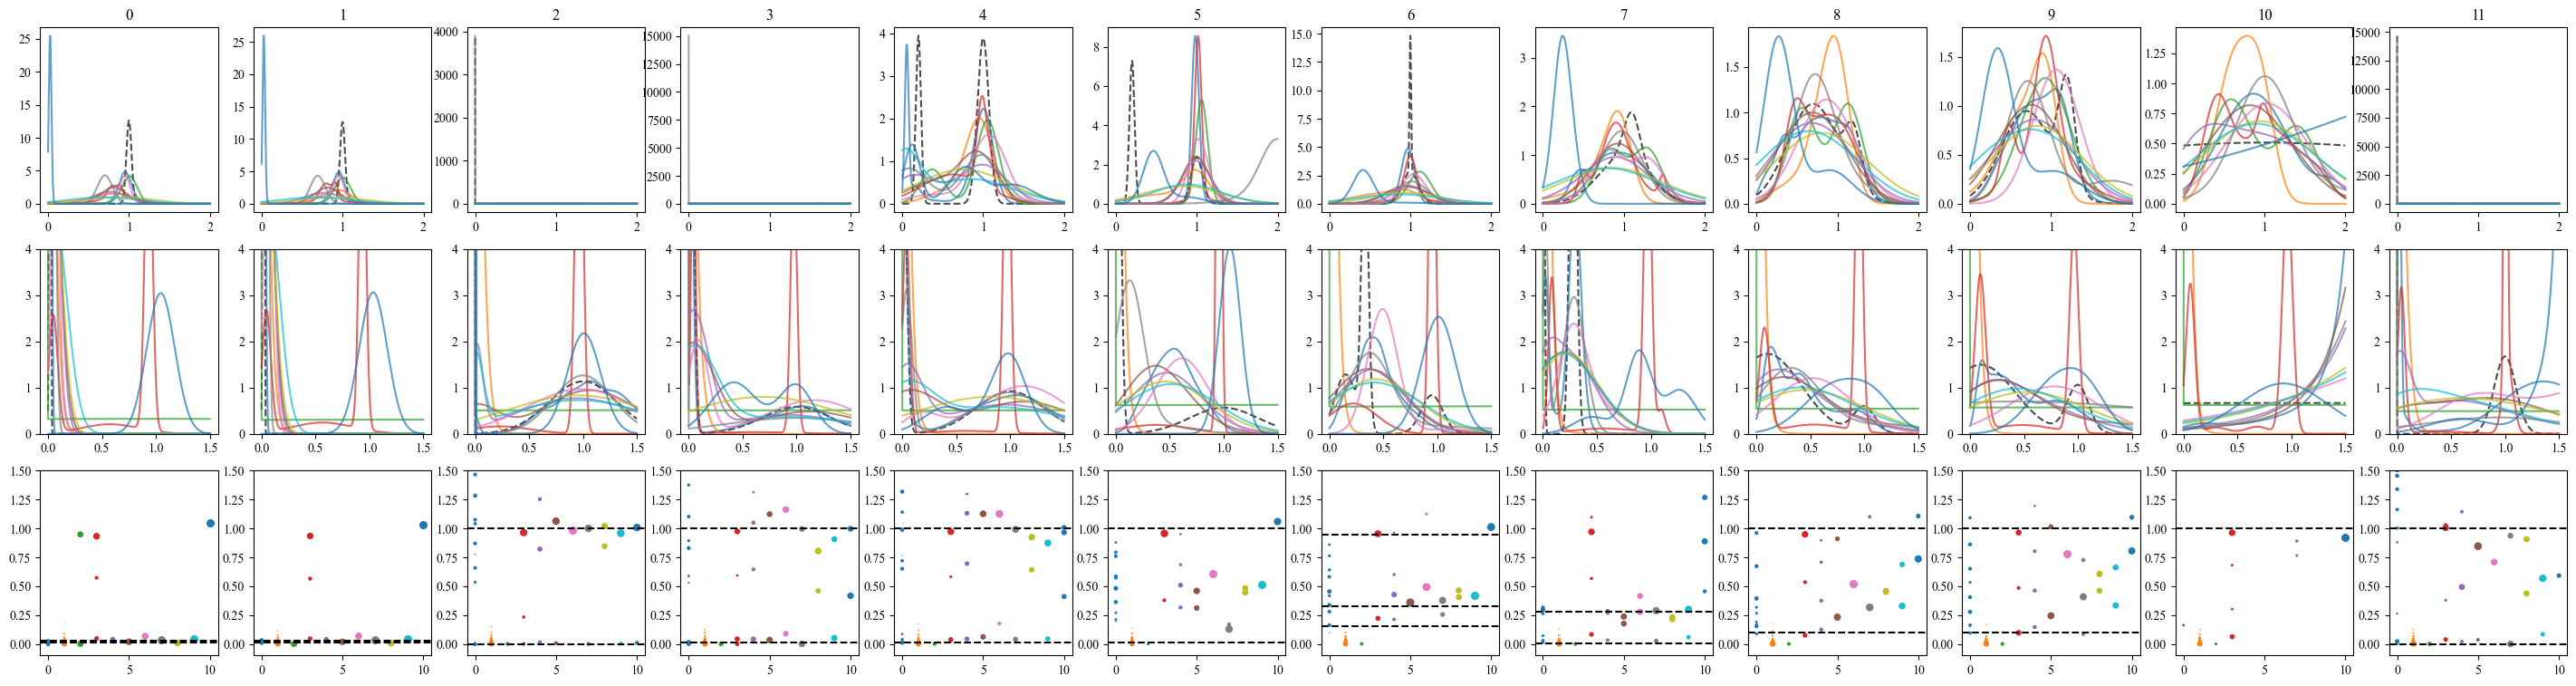

In [13]:
exps = np.arange(12)#[2,3,4,6,7,8,9,10,11]
fig, axes = plt.subplots(3, len(exps), figsize = (len(exps)*3, 3*3))

ax = axes.transpose()

size_support = int(1e4)
x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                      models_phenom().bound_alpha[1], size_support)
    
# x_D = np.logspace(np.log10(models_phenom().bound_D[0]), 
#                   np.log10(models_phenom().bound_D[1]), size_support) 

x_D = np.linspace(0, 1.5, size_support) 

idxe = 0

num_teams = 12

comparison_a = np.zeros((num_teams, len(exps)))
comparison_D = np.zeros((num_teams, len(exps)))
for idxe, exp in enumerate(exps):
    
    true = np.loadtxt(path_ref_ens(track, exp), skiprows = 1, delimiter = ';')  

    if len(true.shape) == 1:
            true = true[:, np.newaxis]

    # true_std = true.copy()
    # true_std[[1,3],:] = true_std[[1,3],:]**2
    
    true_a = multimode_dist(true[:2,:].transpose(), weights = true[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
    true_D = multimode_dist(true[2:4,:].transpose(), weights = true[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)

    ax[idxe, 0].plot(x_alpha, true_a, alpha = 0.7, c = 'k', ls = '--', )
    ax[idxe, 1].plot(x_D, true_D, alpha = 0.7, c = 'k', ls = '--', )

    for mean in true[2,:]:
        ax[idxe,2].axhline(mean,  c = 'k', ls = '--')
    
    for idxl, letter in enumerate(letters[:num_teams]):  
          

        pred = np.loadtxt(path_pred_ens(letter, track, exp), skiprows = 1, delimiter = ';')

        if len(pred.shape) == 1:
            pred = pred[:, np.newaxis]

        if pred[-1,:].sum() > 1:
            pred[-1,:] /= pred[-1,:].sum()

        
            
        pred_a = multimode_dist(pred[:2,:].transpose(), weights = pred[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
        pred_D = multimode_dist(pred[2:4,:].transpose(), weights = pred[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)

        pred_std = pred.copy()

        if df.loc[df.letter == letter].pred_width.values[0] == 'std' or letter == 'B':
    
            pred_std[[1,3],:] = pred_std[[1,3],:]**2
        
        # comparison_a[idxl] = [distribution_distance(true_a, pred_a, x_alpha, metric = metric) for metric in ['wasserstein', 'mae']]
        # comparison_D[idxl] = [distribution_distance(true_D, pred_D, x_D, metric = metric) for metric in ['wasserstein', 'mae']]

        comparison_a[idxl, idxe], comparison_D[idxl, idxe] = error_Ensemble_dataset(true, pred_std)

        
        # Pred
        ax[idxe, 0].plot(x_alpha, pred_a, alpha = 0.7)
        ax[idxe, 1].plot(x_D, pred_D, alpha = 0.7, label = letter)

        ax[idxe, 2].scatter(np.ones_like(pred[2,:])*idxl, pred[2,:], s = 30*pred[-1,:])
    
        ax[idxe, 0].set_title(exp)

        
    
# # plt.setp(ax[:,1], xscale = 'log')#, ylim = (1e-4, 10));
# plt.setp(axes[0,:], ylim = (0, 4), xlim = (-0.1,1.5));
# # plt.setp(



plt.setp(axes[1,:], ylim = (0, 4));
plt.setp(axes[2,:], ylim = (-0.1, 1.5));

In [14]:
mrr = 1/(comparison_a[:-1].mean(1).argsort().argsort()+1) + 1/(comparison_D[:-1].mean(1).argsort().argsort()+1) 
(-mrr).argsort().argsort()

array([ 0,  1,  2,  3,  4,  7,  8,  5,  6,  9, 10])

In [15]:
df_ranking = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')


In [16]:
df_ranking['correct std/var'] = (-mrr).argsort().argsort()+1

In [17]:
df_ranking

,Global rank,Team,W1 (alpha):,W1 (K):,alpha rank,K rank,MRR,correct std/var
0,1,UCL SAM,0.138,0.058,1,4,0.250,1
1,2,DeepSPT,0.267,0.050,9,1,0.222,2
2,3,Nanoninjas,0.192,0.051,3,2,0.167,3
3,4,bjyong,0.188,0.084,2,7,0.129,4
4,5,SPT-HIT,0.231,0.057,6,3,0.100,5
5,6,ICSO UPV,0.218,0.067,4,5,0.090,8
6,7,HSC AI,0.230,0.256,5,8,0.065,9
7,8,Unfriendly AI,0.238,0.072,7,6,0.062,6
8,9,EmetBrown,0.259,0.622,8,11,0.043,7
9,10,BIOMED-UCA,0.275,0.534,10,9,0.042,10


In [240]:
df_ranking = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')
get_letter_from_teams(df_ranking.Team.values)

['I', 'M', 'H', 'O', 'E', 'K', 'L', 'D', 'B', 'F', 'N']

ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey
ey


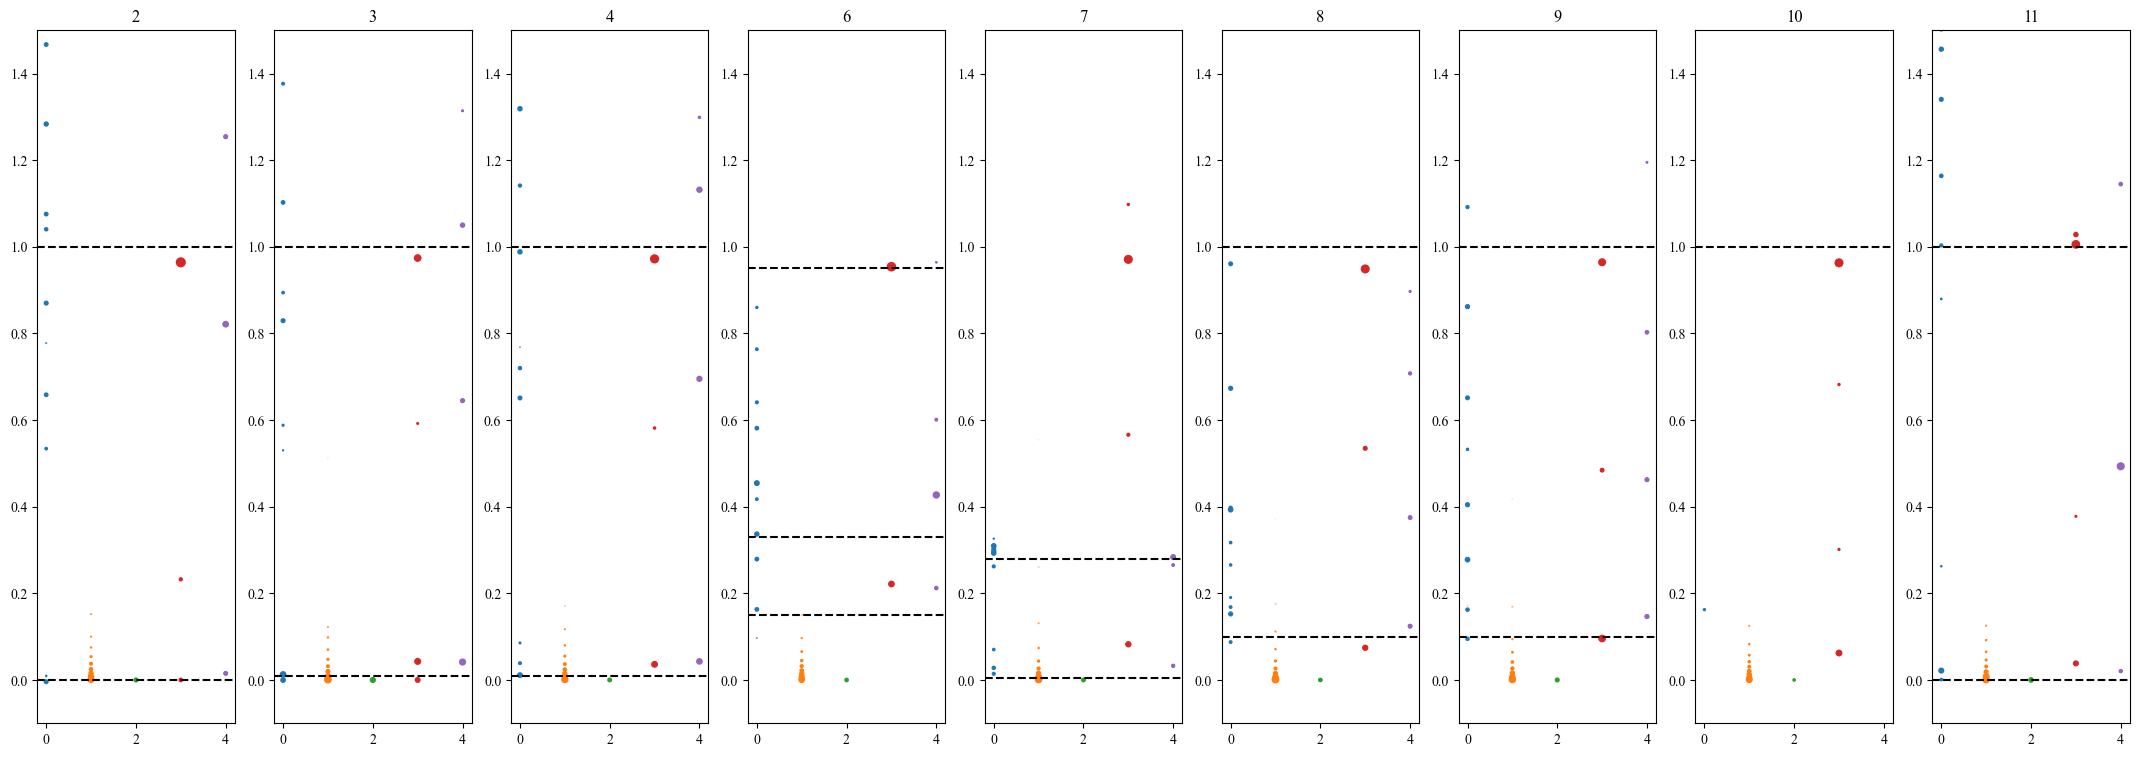

In [274]:
df_ranking = pd.read_csv(f'data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')
letters = get_letter_from_teams(df_ranking.Team.values)


exps = correct_exps
fig, ax = plt.subplots(1, len(exps), figsize = (len(exps)*3, 3*3))


size_support = int(1e4)
x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                      models_phenom().bound_alpha[1], size_support)
    
# x_D = np.logspace(np.log10(models_phenom().bound_D[0]), 
#                   np.log10(models_phenom().bound_D[1]), size_support) 

x_D = np.linspace(0, 1.5, size_support) 

idxe = 0

num_teams = 5

# comparison_a = np.zeros((num_teams, len(exps), 2))
# comparison_D = np.zeros((num_teams, len(exps), 2))
for idxe, exp in enumerate(exps):
    
    true = np.loadtxt(path_ref_ens(track, exp), skiprows = 1, delimiter = ';')

    if len(true.shape) == 1:
            true = true[:, np.newaxis]

    true_a = multimode_dist(true[:2,:].transpose(), weights = true[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
    true_D = multimode_dist(true[2:4,:].transpose(), weights = true[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)


    for mean in true[2,:]:
        ax[idxe].axhline(mean,  c = 'k', ls = '--')
    
    for idxl, letter in enumerate(letters[:num_teams]):  
          

        pred = np.loadtxt(path_pred_ens(letter, track, exp), skiprows = 1, delimiter = ';')

        if len(pred.shape) == 1:
            pred = pred[:, np.newaxis]

        if pred[-1,:].sum() > 1:
            pred[-1,:] /= pred[-1,:].sum()

        if df.loc[df.letter == letter].pred_width.values[0] == 'std' or letter == 'B':
            print('ey')
            pred_std[[1,3],:] = pred_std[[1,3],:]**2

        
            
        pred_a = multimode_dist(pred[:2,:].transpose(), weights = pred[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
        pred_D = multimode_dist(pred[2:4,:].transpose(), weights = pred[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)

        # comparison_a[idxl, idxe] = [distribution_distance(true_a, pred_a, x_alpha, metric = metric) for metric in ['wasserstein', 'mae']]
        # comparison_D[idxl, idxe] = [distribution_distance(true_D, pred_D, x_D, metric = metric) for metric in ['wasserstein', 'mae']]


        ax[idxe].scatter(np.ones_like(pred[2,:])*idxl, pred[2,:], s = 50*pred[-1,:])
    
        ax[idxe].set_title(exp)

        
    
# # plt.setp(ax[:,1], xscale = 'log')#, ylim = (1e-4, 10));
# plt.setp(axes[0,:], ylim = (0, 4), xlim = (-0.1,1.5));
# # plt.setp(



plt.setp(ax, ylim = (-0.1, 1.5));

M
E
M
E
M
E


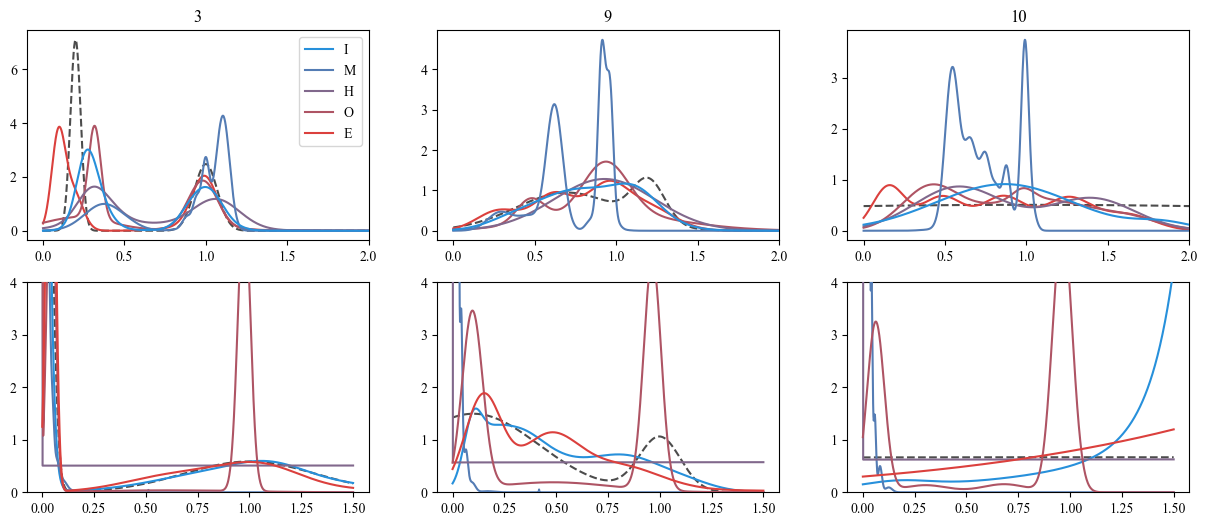

In [277]:
exps = [3,9,10]
fig, axes = plt.subplots(2, len(exps), figsize = (len(exps)*5, 2*3))

ax = axes.transpose()

size_support = 1000
x_alpha = np.linspace(models_phenom().bound_alpha[0], 
                              models_phenom().bound_alpha[1], size_support)
    
x_D = np.linspace(0, 1.5, size_support) 

idxe = 0

num_teams = 5
colors = cmap(np.linspace(0,1,num_teams))
for idxe, exp in enumerate(exps):
    
    true = np.loadtxt(path_ref_ens(track, exp), skiprows = 1, delimiter = ';')

    if len(true.shape) == 1:
            true = true[:, np.newaxis]

    true_a = multimode_dist(true[:2,:].transpose(), weights = true[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
    true_D = multimode_dist(true[2:4,:].transpose(), weights = true[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)

    ax[idxe, 0].plot(x_alpha, true_a, alpha = 0.7, c = 'k', ls = '--', )
    ax[idxe, 1].plot(x_D, true_D, alpha = 0.7, c = 'k', ls = '--', )
    
    for idxl, letter in enumerate(letters[:num_teams]):  
          

        pred = np.loadtxt(path_pred_ens(letter, track, exp), skiprows = 1, delimiter = ';')

        

        if len(pred.shape) == 1:
            pred = pred[:, np.newaxis]

        if pred[-1,:].sum() > 1:
            pred[-1,:] /= pred[-1,:].sum()

        if df.loc[df.letter == letter].pred_width.values[0] == 'std' or letter == 'B':
            print(letter)
            pred[[1,3],:] = pred[[1,3],:]**2
            
        pred_a = multimode_dist(pred[:2,:].transpose(), weights = pred[-1,:], bound = [x_alpha.min(), x_alpha.max()], x = x_alpha)
        pred_D = multimode_dist(pred[2:4,:].transpose(), weights = pred[-1,:], bound = [x_D.min(), x_D.max()], x = x_D)

        
        # # Pred
        # if letter == 'I':
        #     props = {'lw' : 2, 'zorder' : 10, 'c' : colors[idxl]}
        # else:
        #     props = {'c' : colors[idxl]}
            
        ax[idxe, 0].plot(x_alpha, pred_a, c = colors[idxl], label = letter, zorder = 10-idxl)
        ax[idxe, 1].plot(x_D, pred_D, c = colors[idxl], zorder = 10-idxe)
    
        ax[idxe, 0].set_title(exp)
    
# plt.setp(ax[:,1], xscale = 'log')#, ylim = (1e-4, 10));

# plt.setp(axes[0,1], ylim = (0,8))
# plt.setp(axes[0,2], ylim = (0,4))
# plt.setp(axes[0,3], ylim = (0,8))

plt.setp(axes[0,:3], xlim = (-0.1,2));
plt

plt.setp(axes[1,:], ylim = (0, 4));

axes[0,0].legend()


In [161]:
pred

array([[ 6.69401443],
       [13.4475979 ],
       [ 0.92509904],
       [ 0.16025109],
       [ 1.        ]])

# Single trajectory task 

In [69]:
df = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_single.csv')


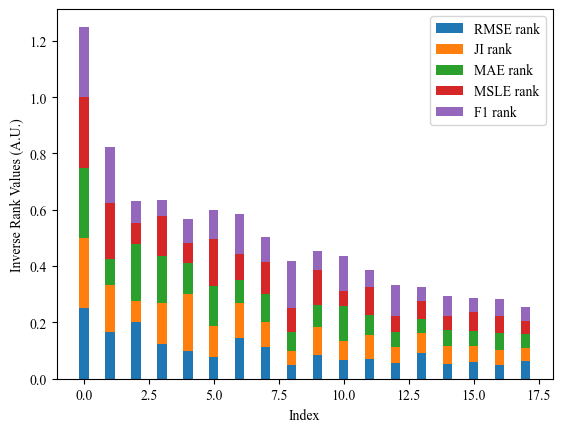

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Filter columns that end with 'rank'
rank_columns = [col for col in df.columns if col.endswith('rank') and col != 'Global rank']


# Extract the inverses of the ranks as a numpy array
inverse_ranks = np.array([1 / (df[col].to_numpy()+3) for col in rank_columns])

# Plotting
indices = np.arange(len(df))
width = 0.35

fig, ax = plt.subplots()
bottom = np.zeros(len(df))

for inv_rank in inverse_ranks:
    ax.bar(indices, inv_rank, width, bottom=bottom)
    bottom += inv_rank

ax.set_xlabel('Index')
ax.set_ylabel('Inverse Rank Values (A.U.)')
ax.legend(rank_columns)

plt.show()


# General analysis figure

In [1422]:
dict_mapping = load_txt_as_dict('data/challenge_phase/team_mapping.txt')
dict_inv = dict((v,k) for k,v in dict_mapping.items())

df_ens = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_ens.csv')
teams_ens = df_ens['Team'].values
letters_ens = [dict_inv[key] for key in teams_ens]

df_st = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_trajs_single.csv')[:-1]
teams_st = df_st['Team'].values
letters_st = [dict_inv[key] for key in teams_st]


df_ens_v = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_videos_ens.csv')
teams_ens_v = df_ens_v['Team'].values
letters_ens_v = [dict_inv[key] for key in teams_ens_v]

df_st_v = pd.read_csv('data/challenge_phase/final_leaderboards/Final_leaderboard_videos_single.csv')
teams_st_v = df_st_v['Team'].values
letters_st_v = [dict_inv[key] for key in teams_st_v]

In [1620]:
method_ens = [None,None,None,None,'GMM','GMM',None,'cluster','GMM',None,'cluster','cluster',None,'cluster','GMM',None,None,None]
letters = 'ABCDEFGHIJKLMNOPQR'
methods_ens = {l : v for l, v in zip(letters, method_ens)}

df_ens['method'] = [methods_ens[l] for l in get_letter_from_teams(df_ens.Team.values)]
df_ens_v['method'] = [methods_ens[l] for l in get_letter_from_teams(df_ens_v.Team.values)]

In [1621]:
df_ens

,Global rank,Team,W1 (alpha):,W1 (K):,alpha rank,K rank,MRR,method
0,1,UCL SAM,0.138,0.058,1,4,0.250,GMM
1,2,DeepSPT,0.267,0.050,9,1,0.222,None
2,3,Nanoninjas,0.192,0.051,3,2,0.167,cluster
3,4,bjyong,0.188,0.084,2,7,0.129,GMM
4,5,SPT-HIT,0.231,0.057,6,3,0.100,GMM
5,6,ICSO UPV,0.218,0.067,4,5,0.090,cluster
6,7,HSC AI,0.230,0.256,5,8,0.065,cluster
7,8,Unfriendly AI,0.238,0.072,7,6,0.062,None
8,9,EmetBrown,0.259,0.622,8,11,0.043,None
9,10,BIOMED-UCA,0.275,0.534,10,9,0.042,GMM


In [1633]:
colors_m = np.array(['k']*df_ens.shape[0], dtype = np.object_)
colors_m[df_ens['method'].values == 'GMM'] = 'C1'
colors_m[df_ens['method'].values == 'cluster'] = 'C2'

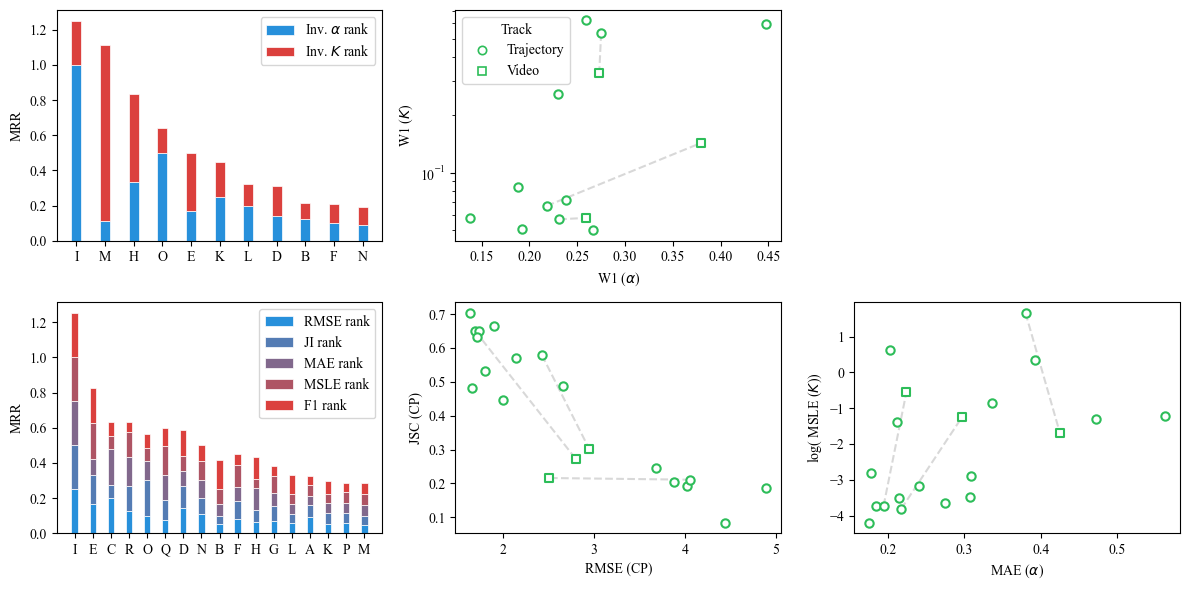

In [1474]:
fig, axs = plt.subplots(2, 3, figsize = (3*4, 2*3), tight_layout = True)
axs[0,-1].set_axis_off()

props_traj = {'facecolor' : 'w', 'edgecolor' : c_comp2, 'lw' : 1.5}
props_video = {'facecolor' : 'w', 'edgecolor' : c_comp2, 'marker' : 's', 'lw' : 1.5}


''' Ensemble '''
# Extract columns as numpy arrays and compute the inverses
inv_alpha_rank = 1 / df_ens['alpha rank'].to_numpy()
inv_k_rank = 1 / df_ens['K rank'].to_numpy()

# Plotting
indices = np.arange(len(inv_alpha_rank))
width = 0.35

axs[0,0].bar(indices, inv_alpha_rank, width, label= r'Inv. $\alpha$ rank', facecolor = c_main, edgecolor = 'w', lw = 0.5)
axs[0,0].bar(indices, inv_k_rank, width, bottom=inv_alpha_rank, label = r'Inv. $K$ rank', facecolor = c_comp, edgecolor = 'w', lw = 0.5)

plt.setp(axs[0,0], ylabel = 'MRR', xticks = np.arange(len(teams_ens)), xticklabels = letters_ens)
axs[0,0].legend()


#### Scatter
axs[0,1].scatter(df_ens['W1 (alpha): '], df_ens['W1 (K): '], **props_traj)
axs[0,1].scatter(df_ens_v['W1 (alpha): '], df_ens_v['W1 (K): '], **props_video)
plt.setp(axs[0,1], xlabel = r'W1 ($\alpha$)', ylabel = r'W1 ($K$)')

''' Single Trajectory '''
# Filter columns that end with 'rank'
rank_columns = [col for col in df_st.columns if col.endswith('rank') and col != 'Global rank']

# Extract the inverses of the ranks as a numpy array
inverse_ranks = np.array([1 / (df_st[col].to_numpy()+3) for col in rank_columns])

# Plotting
indices = np.arange(len(df_st))
width = 0.35

bottom = np.zeros(len(df_st))

colors = cmap(np.linspace(0, 1, len(rank_columns)))
for inv_rank, c, l in zip(inverse_ranks, colors, rank_columns):
    axs[1,0].bar(indices, inv_rank, width, bottom=bottom, facecolor = c, edgecolor = 'w', lw = 0.5, label = l)
    bottom += inv_rank
axs[1,0].legend()
plt.setp(axs[1,0], ylabel = 'MRR', xticks = np.arange(len(teams_st)), xticklabels = letters_st); 

#### Scatter CP
axs[1,1].scatter(df_st['RMSE (CP) '], df_st['JSC (CP) '], **props_traj)
axs[1,1].scatter(df_st_v['RMSE (CP) '], df_st_v['JSC (CP) '], **props_video)
plt.setp(axs[1,1], xlabel = r'RMSE (CP)', ylabel = r'JSC (CP)')

#### Scatter Diff props
axs[1,2].scatter(df_st['MAE (alpha) '], np.log(df_st['MSLE (K) ']), **props_traj)
axs[1,2].scatter(df_st_v['MAE (alpha) '], np.log(df_st_v['MSLE (K) ']), **props_video)
plt.setp(axs[1,2], xlabel = r'MAE ($\alpha$)', ylabel = r'log( MSLE ($K$))')



teams_both_tasks = [['SPT-HIT', 'BIOMED-UCA', 'ICSO UPV'], # Ensemble traj
                    ['SU-FIONA', 'ICSO UPV', 'SPT-HIT'], # Single traj                    
                   ]

for idx_task, teams_to_connect in enumerate(teams_both_tasks):
    
    for team in teams_to_connect:

        if idx_task == 0:
             # Get points for the team in each dataframe
            x1 = df_ens[df_ens['Team'] == team]['W1 (alpha): '].values[0]
            y1 = df_ens[df_ens['Team'] == team]['W1 (K): '].values[0]
            x2 = df_ens_v[df_ens_v['Team'] == team]['W1 (alpha): '].values[0]
            y2 = df_ens_v[df_ens_v['Team'] == team]['W1 (K): '].values[0]

            axs[0, 1].plot([x1, x2], [y1, y2], color='gray', alpha=0.3, zorder = -24, ls = '--')

        else:
            # Get points for the team in each dataframe
            x1 = df_st[df_st['Team'] == team]['RMSE (CP) '].values[0]
            y1 = df_st[df_st['Team'] == team]['JSC (CP) '].values[0]
            x2 = df_st_v[df_st_v['Team'] == team]['RMSE (CP) '].values[0]
            y2 = df_st_v[df_st_v['Team'] == team]['JSC (CP) '].values[0]
        
            # Plot a line connecting the points
            axs[1, 1].plot([x1, x2], [y1, y2], color='gray', alpha=0.3, zorder = -24, ls = '--')
    
            # Get points for the team in each dataframe
            x1 = df_st[df_st['Team'] == team]['MAE (alpha) '].values[0]
            y1 = np.log(df_st[df_st['Team'] == team]['MSLE (K) '].values[0])
            x2 = df_st_v[df_st_v['Team'] == team]['MAE (alpha) '].values[0]
            y2 = np.log(df_st_v[df_st_v['Team'] == team]['MSLE (K) '].values[0])
            
            # Plot a line connecting the points
            axs[1, 2].plot([x1, x2], [y1, y2], color='gray', alpha=0.3, zorder = -24, ls = '--')

# Create handles for the legend
traj_handle = mlines.Line2D([], [], markerfacecolor= 'w', markeredgecolor = c_comp2, marker='o', linestyle='None', label='Trajectory', markeredgewidth = 1.2)
video_handle = mlines.Line2D([], [], markerfacecolor= 'w', markeredgecolor = c_comp2, marker='s', linestyle='None', label='Video', markeredgewidth = 1.2)

# Add legend to the plot
axs[0,1].legend(handles=[traj_handle, video_handle], title = 'Track')
axs[0,1].set_yscale('log')

## Metrics vs. # CP

In [7]:
def condition_CP(df, num_cp_max):
    '''
    Considers that df has two columns 'changepoints' and 'traj_idx' and returns the values
    of 'traj_idx' where len(changepoints) == num_cp_max 
    
    Note: (num_cp_max = 1 is no changepoint).
    '''
    
    return df.loc[df['changepoints'].apply(len) == num_cp_max, 'traj_idx'].values.astype(int)
    
    

In [ ]:
num_cps = np.arange(1,10)

df = pd.read_csv(path_folders +'final_leaderboards/Final_leaderboard_trajs_single.csv')
teams = df['Team'].values
dict_mapping = load_txt_as_dict(path_folders+'team_mapping.txt')
dict_inv = dict((v,k) for k,v in dict_mapping.items())
letters = [dict_inv[key] for key in teams][:5]

# Including not from challenge (andi-j)
# letters += ['model_v2.2']

metrics = np.zeros((len(num_cps), 5, len(letters)))

for idxc, cp_max in enumerate(num_cps):
    metrics[idxc] = metrics_with_codition_st(letters_teams = letters, condition=condition_CP, num_cp_max = cp_max)

# np.save('data/challenge_phase/analysis_data/metrics_vs_cp.npy', metrics)

[2, 3, 4, 6, 7, 8, 9, 11]


  0%|          | 0/8 [00:00<?, ?it/s]

[2, 3, 4, 6, 7, 8, 9, 11]


  0%|          | 0/8 [00:00<?, ?it/s]

[2, 3, 4, 6, 7, 8, 9, 11]


...

  0%|          | 0/8 [00:00<?, ?it/s]

[2, 3, 4, 6, 7, 8, 9, 11]


  0%|          | 0/8 [00:00<?, ?it/s]

[2, 3, 4, 6, 7, 8, 9, 11]


  0%|          | 0/8 [00:00<?, ?it/s]

In [27]:
np.save('/home/gorka/overleaf/andi-j/figures/andi2_metrics_vs_cp.npy', metrics)

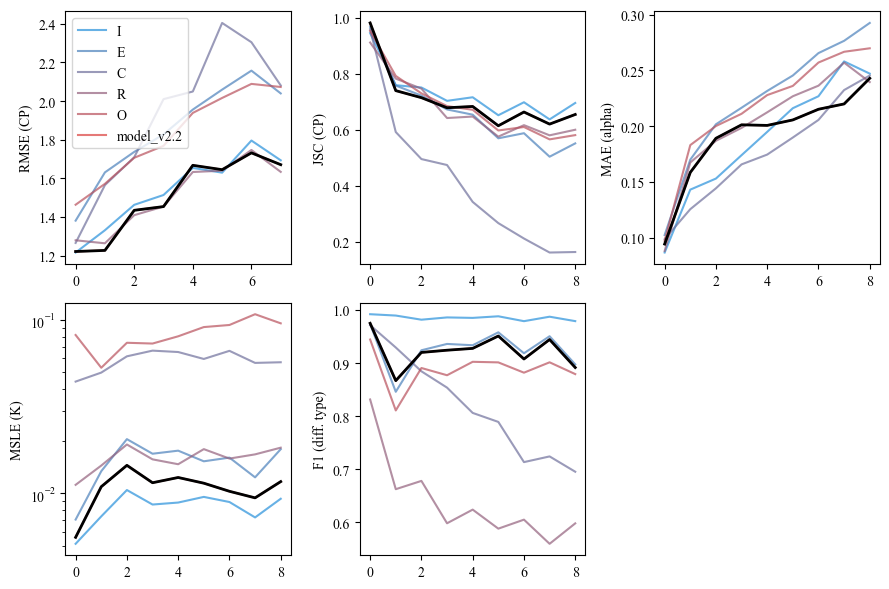

In [24]:
# np.save('data/challenge_phase/analysis_data/metrics_vs_cp.npy', metrics)


fig, axs = plt.subplots(2,3, tight_layout = True, figsize = (3*3, 2*3))

metric_names = [metric[:-1] for metric in df.columns[2:7]]


colors = cmap(np.linspace(0,1,metrics.shape[-1]))
for idxm, (metric, ax) in enumerate(zip(metric_names, axs.flatten())):

    start = 1 if idxm == 0 else 0

    for idxt in range(metrics.shape[-1]):
        ax.plot(metrics[start:,idxm,idxt], c = colors[idxt], alpha = 0.7, label = letters[idxt])

    # ax.plot(metrics[start:,idxm,:].mean(1), c = 'k', lw = 2)
    ax.plot(metrics[start:,idxm,-1], c = 'k', lw = 2)



    if metric == 'MSLE (K)':
        ax.set_yscale('log')
        
        
    ax.set_ylabel(metric)

axs[0,0].legend()
axs[-1,-1].set_axis_off()

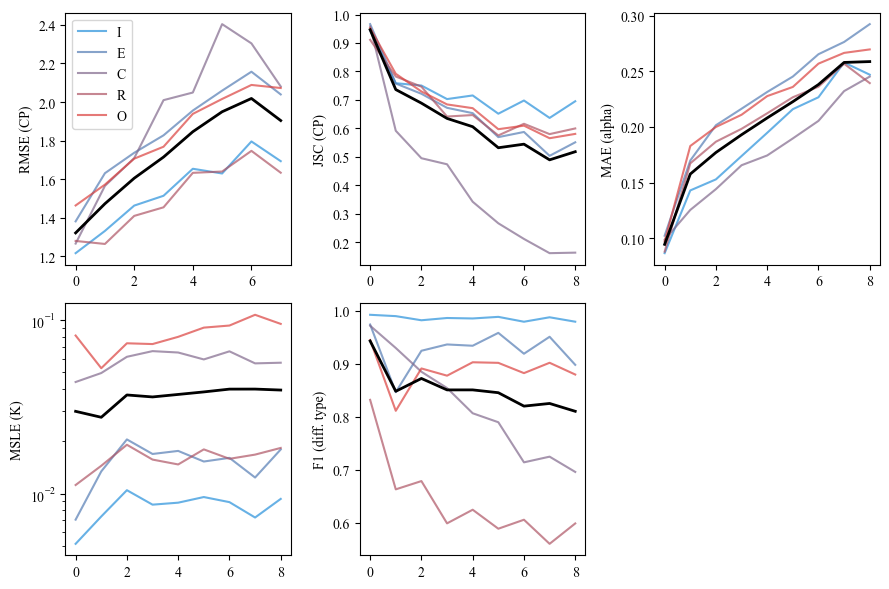

In [ ]:
# np.save('data/challenge_phase/analysis_data/metrics_vs_cp.npy', metrics)


fig, axs = plt.subplots(2,3, tight_layout = True, figsize = (3*3, 2*3))

metric_names = [metric[:-1] for metric in df.columns[2:7]]


colors = cmap(np.linspace(0,1,metrics.shape[-1]))
for idxm, (metric, ax) in enumerate(zip(metric_names, axs.flatten())):

    start = 1 if idxm == 0 else 0

    for idxt in range(metrics.shape[-1]):
        ax.plot(metrics[start:,idxm,idxt], c = colors[idxt], alpha = 0.7, label = letters[idxt])

    ax.plot(metrics[start:,idxm,:].mean(1), c = 'k', lw = 2)


    if metric == 'MSLE (K)':
        ax.set_yscale('log')
        
        
    ax.set_ylabel(metric)

axs[0,0].legend()
axs[-1,-1].set_axis_off()